# **Project Name**    - Video Game Sales and Engagement Analysis

##### **Project Type**    - EDA
##### **Contribution**    - Individual
##### **Name**            - Prajwal Veerendra H


## Project Summary
This project combines two complementary datasets to explore video game commercial performance and player engagement. The sales dataset (`vgsales.csv`) contains game, platform, genre, publisher, regional sales, and global sales fields. The engagement dataset (`games.csv`) contains titles, release dates, teams, user ratings, reviews, plays, currently playing counts, backlogs, and wishlists. The notebook uses Python, Pandas, NumPy, Matplotlib, and Seaborn to inspect, clean, compare, and visualize these records.

The analysis examines sales by genre and platform, regional sales patterns, release trends, and the most commercially successful titles. It also explores engagement signals such as plays, ratings, wishlists, backlogs, and developer teams. Where titles can be matched between the two datasets, the notebook investigates how commercial sales relate to engagement measures. These comparisons are exploratory: sales and engagement come from different sources and may cover different time periods, populations, and definitions.

The findings can help frame questions about genre strategy, platform coverage, regional audience differences, and the relationship between attention and sales. However, the datasets do not provide costs, profit margins, marketing spend, player retention, or causal evidence. Sales volume should therefore not be treated as profit, and high ratings or wishlists should not automatically be interpreted as future revenue.

## Problem Statement
Video game performance can be viewed from both a commercial perspective and an engagement perspective, but the two datasets contain different measures and may not contain the same titles. The project investigates how sales vary by genre, platform, year, and region, how engagement is distributed across games and genres, and what can cautiously be inferred when matching titles across datasets.

## Business Objective
To summarize historical sales patterns and player engagement indicators in a clear, evidence-based way, identify potential opportunities for further investigation, and highlight limitations that should be considered before making business decisions.

## Datasets
- **`vgsales.csv`**: game name, platform, release year, genre, publisher, North America / Europe / Japan / other-region sales, and global sales.
- **`games.csv`**: game title, release date, developer/team, rating, number of reviews, plays, playing, backlogs, wishlists, genres, and descriptive review fields.

## Tools and Workflow
1. Load and inspect both datasets.
2. Review missing values and data types.
3. Clean selected fields and convert engagement counts such as `3.9K` into numeric values.
4. Analyze sales and engagement separately.
5. Standardize titles and attempt a title-based merge.
6. Visualize patterns and document the chart choice, findings, business implications, and risks for each chart.
7. Summarize findings, recommendations, and limitations.



# **GitHub Link -**

[LINK](https://github.com/Prajwal-VH?tab=repositories)

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 20 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from cycler import cycler
plt.rcParams['axes.prop_cycle'] = cycler(color=['#4472C4', '#ED7D31', '#70AD47', '#A5A5A5', '#FFC000', '#5B9BD5'])


In [2]:
# Load Dataset
data = pd.read_csv("vgsales.csv")
games = pd.read_csv("games.csv")

In [4]:
data.head()


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [5]:
games.head()

,Unnamed: 0,Title,Release Date,Team,Rating,Times Listed,Number of Reviews,Genres,Summary,Reviews,Plays,Playing,Backlogs,Wishlist
0,0,Elden Ring,"Feb 25, 2022","['Bandai Namco Entertainment', 'FromSoftware']",4.5,3.9K,3.9K,"['Adventure', 'RPG']","Elden Ring is a fantasy, action and open world...","[""The first playthrough of elden ring is one o...",17K,3.8K,4.6K,4.8K
1,1,Hades,"Dec 10, 2019",['Supergiant Games'],4.3,2.9K,2.9K,"['Adventure', 'Brawler', 'Indie', 'RPG']",A rogue-lite hack and slash dungeon crawler in...,['convinced this is a roguelike for people who...,21K,3.2K,6.3K,3.6K
2,2,The Legend of Zelda: Breath of the Wild,"Mar 03, 2017","['Nintendo', 'Nintendo EPD Production Group No...",4.4,4.3K,4.3K,"['Adventure', 'RPG']",The Legend of Zelda: Breath of the Wild is the...,['This game is the game (that is not CS:GO) th...,30K,2.5K,5K,2.6K
3,3,Undertale,"Sep 15, 2015","['tobyfox', '8-4']",4.2,3.5K,3.5K,"['Adventure', 'Indie', 'RPG', 'Turn Based Stra...","A small child falls into the Underground, wher...",['soundtrack is tied for #1 with nier automata...,28K,679,4.9K,1.8K
4,4,Hollow Knight,"Feb 24, 2017",['Team Cherry'],4.4,3K,3K,"['Adventure', 'Indie', 'Platform']",A 2D metroidvania with an emphasis on close co...,"[""this games worldbuilding is incredible, with...",21K,2.4K,8.3K,2.3K


In [6]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  str    
 2   Platform      16598 non-null  str    
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  str    
 5   Publisher     16540 non-null  str    
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(6), int64(1), str(4)
memory usage: 2.1 MB


In [7]:
games.info()

<class 'pandas.DataFrame'>
RangeIndex: 1512 entries, 0 to 1511
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         1512 non-null   int64  
 1   Title              1512 non-null   str    
 2   Release Date       1512 non-null   str    
 3   Team               1511 non-null   str    
 4   Rating             1499 non-null   float64
 5   Times Listed       1512 non-null   str    
 6   Number of Reviews  1512 non-null   str    
 7   Genres             1512 non-null   str    
 8   Summary            1511 non-null   str    
 9   Reviews            1512 non-null   str    
 10  Plays              1512 non-null   str    
 11  Playing            1512 non-null   str    
 12  Backlogs           1512 non-null   str    
 13  Wishlist           1512 non-null   str    
dtypes: float64(1), int64(1), str(12)
memory usage: 2.9 MB


In [8]:
data.isnull().sum()

Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64

In [9]:
games.isnull().sum()

Unnamed: 0            0
Title                 0
Release Date          0
Team                  1
Rating               13
Times Listed          0
Number of Reviews     0
Genres                0
Summary               1
Reviews               0
Plays                 0
Playing               0
Backlogs              0
Wishlist              0
dtype: int64

In [10]:
# Remove rows where Publisher is missing
data.dropna(subset=['Publisher'], inplace=True)

# Fill missing Year values using forward fill
data['Year'] = data['Year'].ffill()

In [11]:
games.dropna(subset=['Rating'], inplace=True)
games.dropna(subset=['Team'], inplace=True)

In [12]:
print(data.isnull().sum())
data.head()

Rank            0
Name            0
Platform        0
Year            0
Genre           0
Publisher       0
NA_Sales        0
EU_Sales        0
JP_Sales        0
Other_Sales     0
Global_Sales    0
dtype: int64


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [13]:
print(games.isnull().sum())
games.head()

Unnamed: 0           0
Title                0
Release Date         0
Team                 0
Rating               0
Times Listed         0
Number of Reviews    0
Genres               0
Summary              0
Reviews              0
Plays                0
Playing              0
Backlogs             0
Wishlist             0
dtype: int64


,Unnamed: 0,Title,Release Date,Team,Rating,Times Listed,Number of Reviews,Genres,Summary,Reviews,Plays,Playing,Backlogs,Wishlist
0,0,Elden Ring,"Feb 25, 2022","['Bandai Namco Entertainment', 'FromSoftware']",4.5,3.9K,3.9K,"['Adventure', 'RPG']","Elden Ring is a fantasy, action and open world...","[""The first playthrough of elden ring is one o...",17K,3.8K,4.6K,4.8K
1,1,Hades,"Dec 10, 2019",['Supergiant Games'],4.3,2.9K,2.9K,"['Adventure', 'Brawler', 'Indie', 'RPG']",A rogue-lite hack and slash dungeon crawler in...,['convinced this is a roguelike for people who...,21K,3.2K,6.3K,3.6K
2,2,The Legend of Zelda: Breath of the Wild,"Mar 03, 2017","['Nintendo', 'Nintendo EPD Production Group No...",4.4,4.3K,4.3K,"['Adventure', 'RPG']",The Legend of Zelda: Breath of the Wild is the...,['This game is the game (that is not CS:GO) th...,30K,2.5K,5K,2.6K
3,3,Undertale,"Sep 15, 2015","['tobyfox', '8-4']",4.2,3.5K,3.5K,"['Adventure', 'Indie', 'RPG', 'Turn Based Stra...","A small child falls into the Underground, wher...",['soundtrack is tied for #1 with nier automata...,28K,679,4.9K,1.8K
4,4,Hollow Knight,"Feb 24, 2017",['Team Cherry'],4.4,3K,3K,"['Adventure', 'Indie', 'Platform']",A 2D metroidvania with an emphasis on close co...,"[""this games worldbuilding is incredible, with...",21K,2.4K,8.3K,2.3K


In [14]:
# Calculate total sales for each Genre
totalsales = round(data.groupby('Genre').sum(numeric_only=True), 0)
totalsales.reset_index(inplace=True)

# Calculate average sales for each Genre
avgsales = round(data.groupby('Genre').mean(numeric_only=True), 2)
avgsales.reset_index(inplace=True)

# Display results
print("Total Sales by Genre:")
display(totalsales)

print("Average Sales by Genre:")
display(avgsales)

Total Sales by Genre:


,Genre,Rank,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,Action,26361435,6644087.0,878.0,525.0,159.0,187.0,1750.0
1,Adventure,14778800,2574381.0,106.0,64.0,52.0,17.0,239.0
2,Fighting,6476418,1695936.0,222.0,100.0,87.0,36.0,446.0
3,Misc,14667633,3436533.0,405.0,214.0,108.0,75.0,802.0
4,Platform,6118339,1771374.0,447.0,201.0,131.0,52.0,831.0
5,Puzzle,5586639,1165063.0,124.0,51.0,57.0,13.0,245.0
6,Racing,9927387,2502098.0,359.0,238.0,57.0,77.0,732.0
7,Role-Playing,12002392,2982442.0,327.0,188.0,352.0,60.0,927.0
8,Shooter,9623676,2623745.0,583.0,313.0,38.0,103.0,1037.0
9,Simulation,7426751,1731640.0,183.0,113.0,64.0,32.0,392.0


Average Sales by Genre:


,Genre,Rank,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,Action,7966.59,2007.88,0.27,0.16,0.05,0.06,0.53
1,Adventure,11527.93,2008.10,0.08,0.05,0.04,0.01,0.19
2,Fighting,7655.34,2004.65,0.26,0.12,0.10,0.04,0.53
3,Misc,8567.54,2007.32,0.24,0.12,0.06,0.04,0.47
4,Platform,6921.20,2003.82,0.51,0.23,0.15,0.06,0.94
5,Puzzle,9615.56,2005.27,0.21,0.09,0.10,0.02,0.42
6,Racing,7954.64,2004.89,0.29,0.19,0.05,0.06,0.59
7,Role-Playing,8076.98,2007.03,0.22,0.13,0.24,0.04,0.62
8,Shooter,7357.55,2005.92,0.45,0.24,0.03,0.08,0.79
9,Simulation,8605.74,2006.54,0.21,0.13,0.07,0.04,0.45


Action Genre has the Highest Global sales as well as Global sales Average

In [15]:
genre_sales_summary=[]
for i in range(0,len(totalsales)):
    one ={
	    'Genre' : totalsales.iloc[i]['Genre'],
	    'Total_Sales' : totalsales.iloc[i]['Global_Sales'],
	    'Avg_Sales' : avgsales.iloc[i]['Global_Sales']
	    }
    genre_sales_summary.append(one)
genre_sales_summary=pd.DataFrame(genre_sales_summary)
genre_sales_summary.sort_values('Total_Sales',inplace=True)

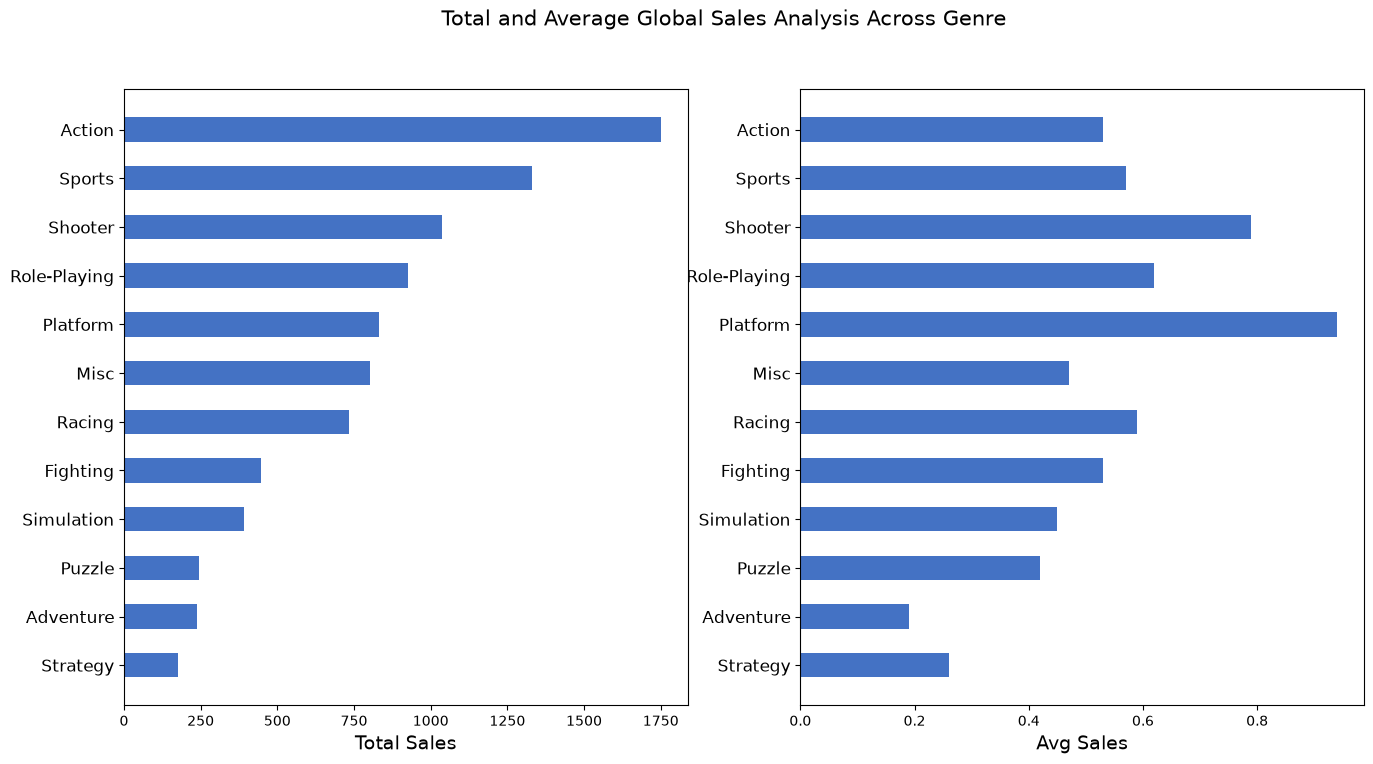

In [16]:
plt.figure(figsize=(16,8))
plt.suptitle('Total and Average Global Sales Analysis Across Genre',fontsize=15)
plt.subplot(121)
plt.barh(genre_sales_summary['Genre'],genre_sales_summary['Total_Sales'],height=0.5)
plt.xlabel('Total Sales',fontsize=14)
plt.yticks(fontsize=12)
plt.subplot(122)
plt.barh(genre_sales_summary['Genre'],genre_sales_summary['Avg_Sales'],height=0.5)
plt.xlabel('Avg Sales',fontsize=14)
plt.yticks(fontsize=12)
plt.show()

### Chart Interpretation — Total and Average Global Sales by Genre

##### 1. Why did you pick this specific chart?
Two horizontal bar charts make it easy to compare both total global sales and average global sales across genres. Showing both measures avoids relying only on totals, which can be higher simply because a genre has more entries.

##### 2. What insights were found?
In the sales dataset, Action has the highest total global sales (about 1,750 million units as recorded in the source), followed by Sports and Shooter. Platform has the highest average global sales per record, at roughly 0.94 million. This shows that the genre with the largest cumulative sales is not necessarily the genre with the highest average sales per listed record.

##### 3. Will the gained insights help create a positive business impact?
These comparisons can inform further research into genre portfolio balance, marketing, and publishing strategy. Total sales can indicate broad historical demand, while average sales can help flag genres with stronger typical performance.

##### Are there any insights that lead to negative growth? Justify with specific reasons.
Treating total sales as a guarantee of future success could lead to overinvestment in a genre. Lower average sales in some genres may also reflect niche audiences, differences in release volume, or historical platform mix rather than weak audience interest. The chart does not include development cost or profit.


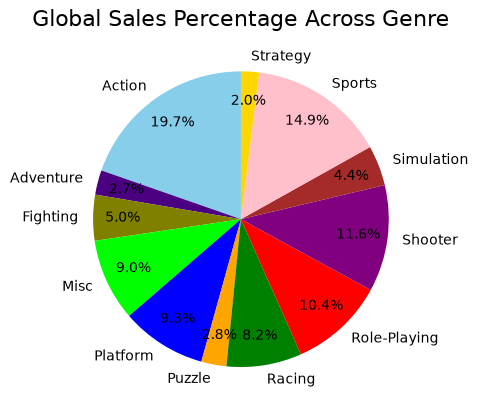

In [17]:
color=['skyblue','indigo','olive','lime','blue','orange','green','red','purple','brown','pink','gold']
plt.pie(totalsales.Global_Sales,labels=totalsales.Genre,pctdistance=0.8,labeldistance=1.1,autopct='%1.1f%%',startangle=90,colors=color,)
plt.title('Global Sales Percentage Across Genre',fontsize=16)
plt.show()

### Chart Interpretation — Percentage of Global Sales by Genre

##### 1. Why did you pick this specific chart?
A pie chart shows how each genre contributes to the total global sales represented in the dataset, making the overall composition visible at a glance.

##### 2. What insights were found?
Action accounts for the largest share of total sales, with Sports and Shooter also contributing substantial portions. Strategy and Adventure contribute comparatively smaller shares in this historical sales dataset.

##### 3. Will the gained insights help create a positive business impact?
The share comparison can help stakeholders understand which genres have historically contributed most to recorded sales and decide where deeper market research may be worthwhile.

##### Are there any insights that lead to negative growth? Justify with specific reasons.
A smaller share does not necessarily mean a genre is unprofitable or should be discontinued. Pie charts also become difficult to compare when many categories have similar shares; detailed decisions should use the underlying values and profitability data.


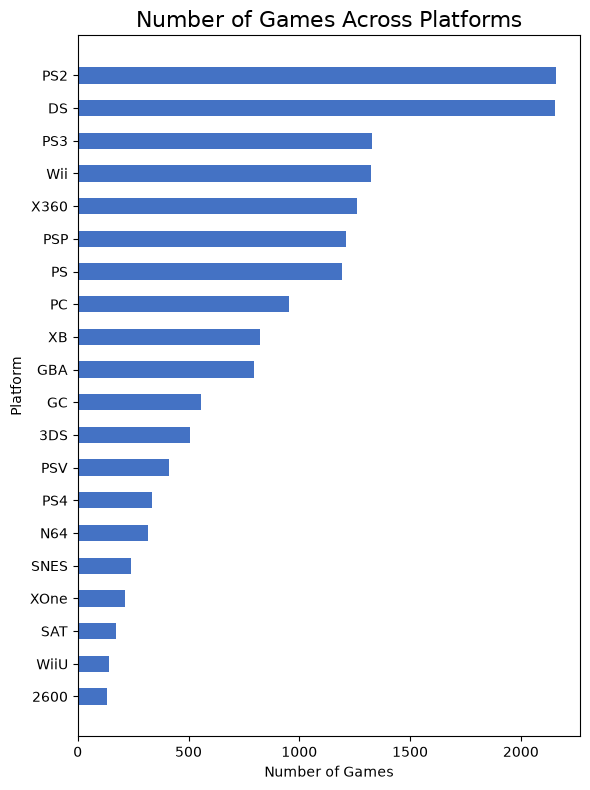

In [18]:
# Count games for each platform
platform = data['Platform'].value_counts().reset_index()

# Rename columns
platform.columns = ['Platform', 'Number of Games']

# Select the top 20 platforms
platform = platform.head(20)

# Sort by number of games
platform = platform.sort_values('Number of Games')

# Plot horizontal bar chart
plt.figure(figsize=(6, 8))
plt.barh(platform['Platform'], platform['Number of Games'], height=0.5)

plt.title('Number of Games Across Platforms', fontsize=16)
plt.xlabel('Number of Games')
plt.ylabel('Platform')
plt.tight_layout()
plt.show()

### Chart Interpretation — Number of Games Across Platforms

##### 1. Why did you pick this specific chart?
A horizontal bar chart is suitable for ranking platforms by the number of records, and it keeps platform labels readable.

##### 2. What insights were found?
The dataset contains the largest number of game records for PS2 and DS, followed by PS3, Wii, and Xbox 360. This measures how many titles are recorded for each platform, not how many consoles were sold or how many players used the platform.

##### 3. Will the gained insights help create a positive business impact?
The count can help describe catalogue coverage and identify platforms with many releases for subsequent sales-per-title analysis.

##### Are there any insights that lead to negative growth? Justify with specific reasons.
A platform with many releases may also have intense competition among titles. The record count alone cannot establish platform demand, sales efficiency, or future growth; it should be considered alongside sales and market context.


In [19]:
Genre=[]
North_America=[]
Europe=[]
Japan=[]
Other=[]
for i in range(0,len(totalsales)):
    Genre.append(totalsales.iloc[i].Genre)
    net=100/totalsales.iloc[i].Global_Sales
    North_America.append(round(totalsales.iloc[i].NA_Sales*net,4))
    Europe.append(round(totalsales.iloc[i].EU_Sales*net,4))
    Japan.append(round(totalsales.iloc[i].JP_Sales*net,4))
    Other.append(round(totalsales.iloc[i].Other_Sales*net,4))

Genre=np.array(Genre)
North_America=np.array(North_America)
Europe=np.array(Europe)
Japan=np.array(Japan)
Other=np.array(Other)

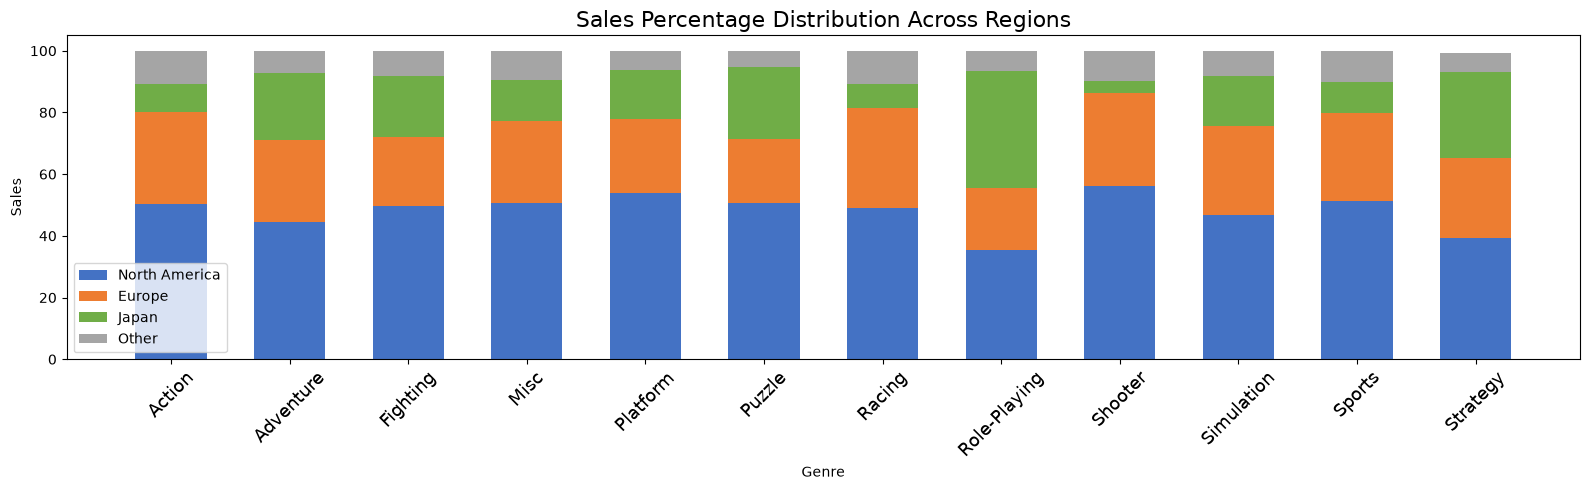

In [20]:
# Create positions for the genres
ind = np.arange(len(Genre))
width = 0.6

plt.figure(figsize=(16, 5))

# Create stacked bars
plt.bar(ind, North_America, width, label='North America')
plt.bar(ind, Europe, width, bottom=North_America, label='Europe')

plt.bar(
    ind, Japan, width,
    bottom=np.array(North_America) + np.array(Europe),
    label='Japan'
)

plt.bar(
    ind, Other, width,
    bottom=np.array(North_America) + np.array(Europe) + np.array(Japan),
    label='Other'
)

# Add labels and title
plt.xticks(ind, Genre, fontsize=13, rotation=45)
plt.ylabel('Sales')
plt.xlabel('Genre')
plt.legend()
plt.title('Sales Percentage Distribution Across Regions', fontsize=16)

plt.tight_layout()
plt.show()

### Chart Interpretation — Regional Sales Mix by Genre

##### 1. Why did you pick this specific chart?
The stacked bar chart compares the percentage contribution of North America, Europe, Japan, and other regions within each genre, highlighting geographic differences in the sales mix.

##### 2. What insights were found?
North America and Europe contribute strongly to many genres. Japan is relatively more important for Role-Playing games than it is for Shooter games, while North America contributes strongly to Sports and Action sales. These patterns suggest regional preferences differ by genre.

##### 3. Will the gained insights help create a positive business impact?
Regional mix can guide localization research, regional marketing, distribution planning, and the selection of genres for deeper market analysis.

##### Are there any insights that lead to negative growth? Justify with specific reasons.
Using one global marketing strategy may overlook regional differences. However, the chart is based on historical sales and does not include current market size, costs, language support, or platform availability, so it cannot by itself justify regional investment decisions.


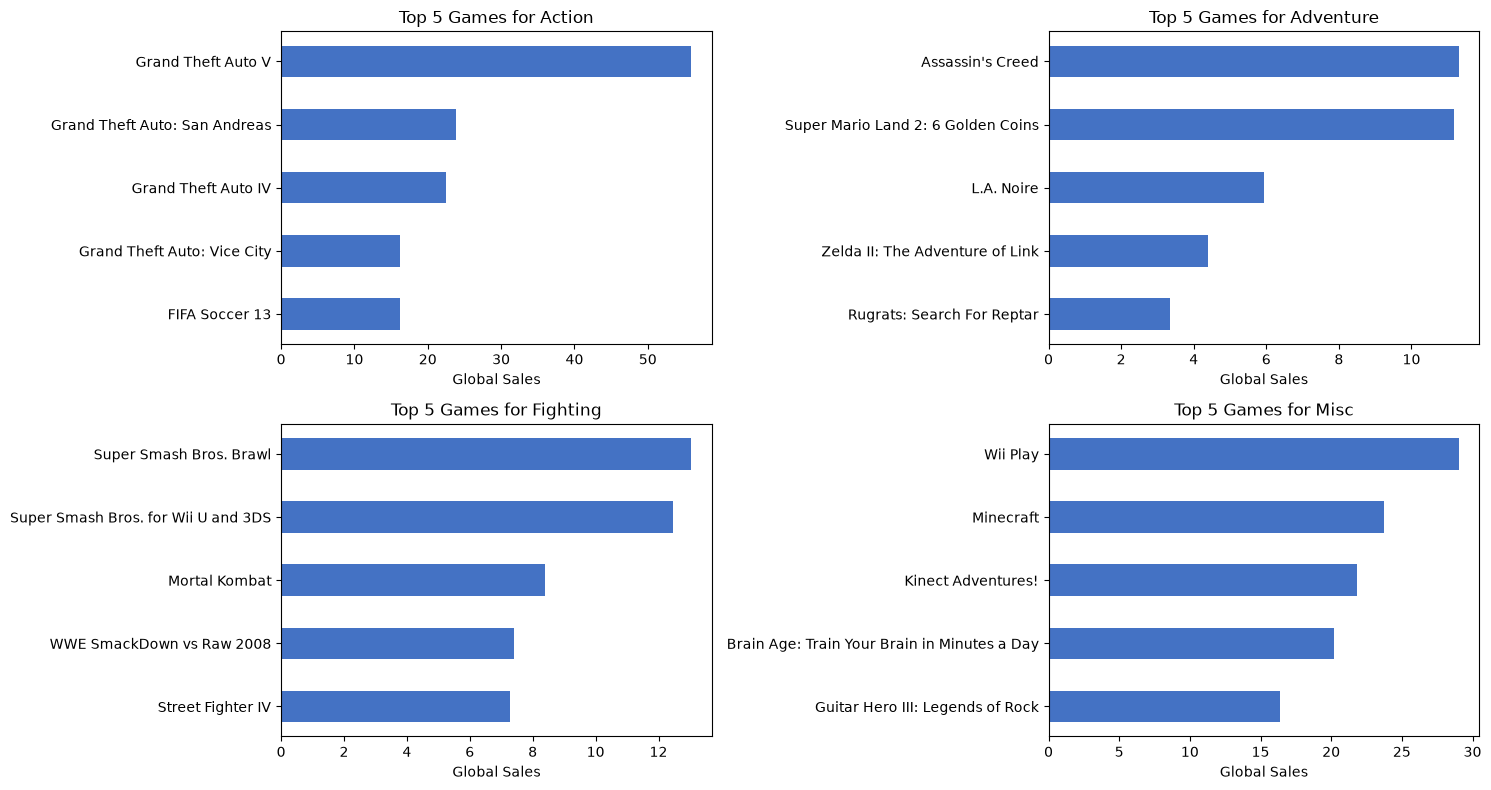

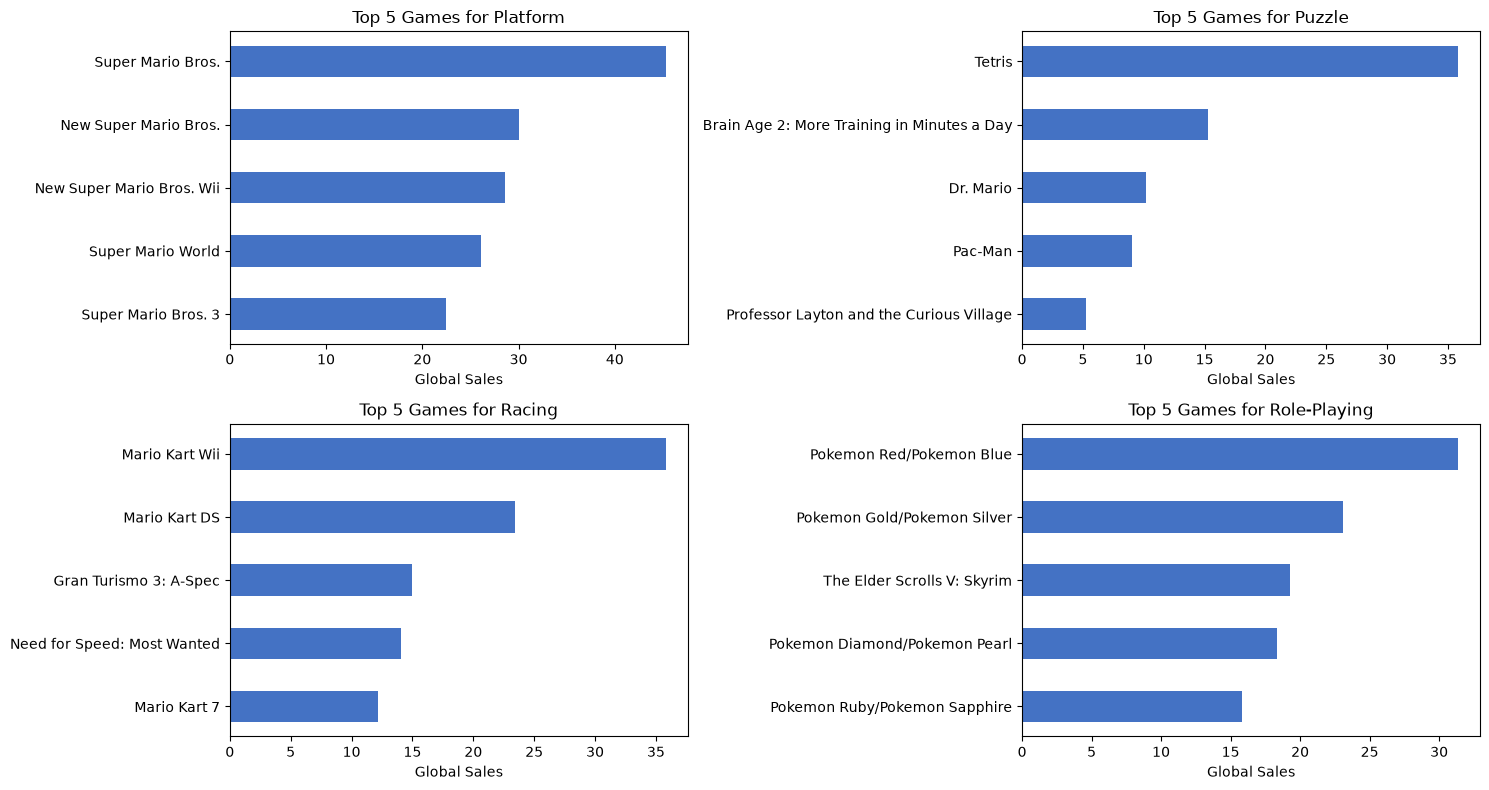

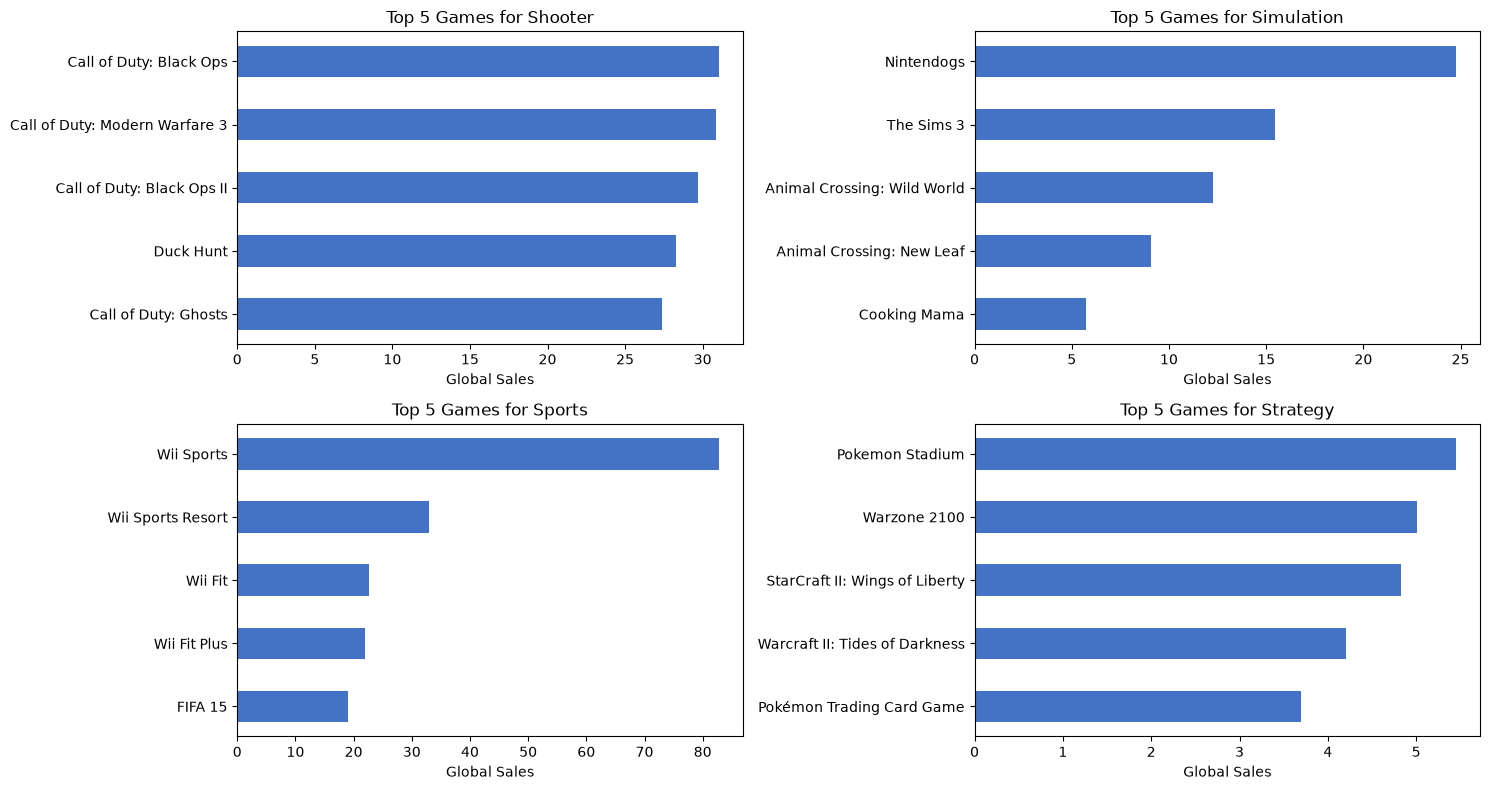

<Figure size 1500x800 with 0 Axes>

In [21]:
df = data.groupby('Genre')

i = 0
plt.figure(figsize=(15, 8))

for genre, genre_games_df in df:
    # Calculate total sales for each game
    genre_games_df = genre_games_df.groupby('Name', as_index=False)['Global_Sales'].sum()

    # Sort by global sales and select the top 5 games
    genre_games_df = genre_games_df.sort_values('Global_Sales', ascending=False).head(5)

    # Reverse order for a clearer horizontal bar chart
    genre_games_df = genre_games_df.sort_values('Global_Sales', ascending=True)

    i += 1
    plt.subplot(2, 2, i)

    plt.barh(
        genre_games_df['Name'],
        genre_games_df['Global_Sales'],
        height=0.5
    )

    plt.title("Top 5 Games for " + str(genre), fontsize=12)
    plt.xlabel("Global Sales")

    if i == 4:
        plt.tight_layout()
        plt.show()

        i = 0
        plt.figure(figsize=(15, 8))

# Display remaining plots if fewer than four genres remain
if i > 0:
    plt.tight_layout()
    plt.show()


### Chart Interpretation — Top-Selling Games Within Each Genre

##### 1. Why did you pick this specific chart?
Small horizontal bar charts allow the leading titles within several genres to be compared while preserving readable game names.

##### 2. What insights were found?
Sales are concentrated in a relatively small set of high-performing titles within many genres. This indicates that genre-level totals can be influenced heavily by individual blockbusters rather than every title in that genre performing similarly.

##### 3. Will the gained insights help create a positive business impact?
The chart can help identify benchmark titles and prompt research into their franchise strength, distribution, release timing, or audience appeal.

##### Are there any insights that lead to negative growth? Justify with specific reasons.
Copying the features of a blockbuster is not a reliable strategy because success may depend on brand recognition, timing, budget, or platform reach. A few high-selling games can also make a genre look stronger than the typical title; median sales and cost data would provide a fuller picture.


In [22]:


# Group data by platform and calculate total sales
platform = data.groupby('Platform').sum(numeric_only=True)

# Sort platforms by Global Sales in descending order
platform.sort_values('Global_Sales', ascending=False, inplace=True)

# Convert index into a regular column
platform.reset_index(inplace=True)

# Select the top 15 platforms
top15 = platform['Platform'].head(15).tolist()

# Group the original data by Genre
df = data.groupby('Genre')

full = []

for genre, table in df:
    # Calculate sales for each platform within the genre
    table = table.groupby('Platform').sum(numeric_only=True).reset_index()

    temp = []

    for each in top15:
        x = table.loc[table['Platform'] == each, 'Global_Sales']

        if len(x) == 0:
            temp.append(0)
        else:
            temp.append(x.iloc[0])

    full.append(np.array(temp))

# Create a DataFrame for comparison
sales_comparison = pd.DataFrame(
    full,
    index=df.groups.keys(),
    columns=top15
)

display(sales_comparison)


,PS2,X360,PS3,Wii,DS,PS,GBA,PSP,PS4,PC,XB,GB,NES,3DS,N64
Action,272.76,242.67,307.88,118.23,115.49,126.96,55.49,64.66,87.06,31.53,49.28,7.92,28.75,57.02,29.58
Adventure,21.16,15.23,22.88,18.43,47.29,20.93,14.49,10.69,4.70,10.09,3.06,17.16,4.38,4.81,0.45
Fighting,89.39,37.64,51.70,23.86,7.20,72.68,4.21,21.97,8.04,0.27,13.55,0.00,6.54,10.46,22.08
Misc,101.14,91.95,47.85,221.06,137.71,44.90,28.50,13.96,7.40,8.56,9.58,13.35,3.59,10.48,11.19
Platform,72.51,11.39,29.85,90.74,77.43,64.21,78.30,17.28,7.01,0.49,9.66,54.91,95.78,32.23,36.13
Puzzle,5.90,0.85,0.60,15.67,84.29,12.08,12.92,5.52,0.02,0.92,0.42,47.47,21.00,5.56,3.41
Racing,156.28,65.99,73.95,61.28,38.64,103.19,18.80,34.73,11.53,4.05,31.49,4.55,9.78,14.49,40.09
Role-Playing,93.50,71.97,75.25,14.06,126.85,78.30,64.21,49.05,25.77,47.78,13.51,88.24,18.78,75.74,3.36
Shooter,108.57,278.50,196.04,28.77,8.20,39.31,3.60,19.77,75.32,45.32,63.55,1.20,35.62,1.29,19.27
Simulation,42.66,14.45,10.79,36.97,131.97,25.33,5.91,6.28,0.77,51.73,7.11,3.55,0.00,27.08,10.19


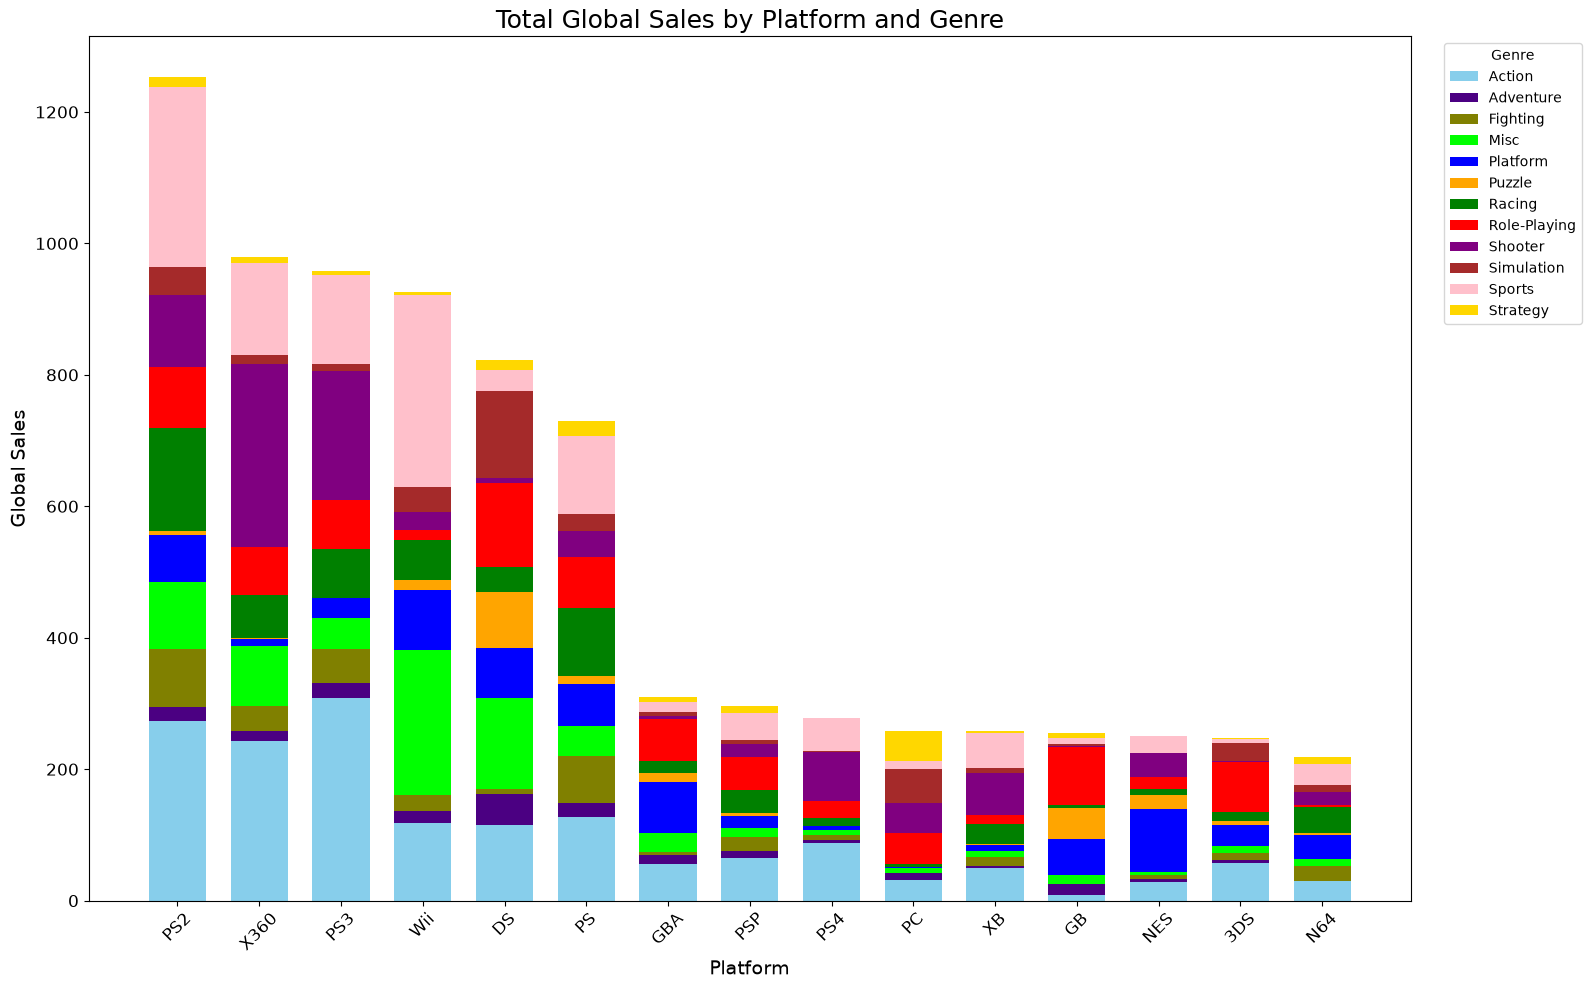

In [23]:
# Initialize the bottom positions for the stacked bars
prev = np.zeros(len(top15))
ind = np.arange(len(top15))
px = []

plt.figure(figsize=(16, 10))

# Plot each genre as a stacked segment
for i in range(len(Genre)):
    bars = plt.bar(
        ind,
        full[i],
        width=0.7,
        bottom=prev,
        color=color[i],
        label=Genre[i]
    )

    px.append(bars)
    prev = prev + full[i]

# Format the chart
plt.xticks(ind, top15, fontsize=12, rotation=45)
plt.yticks(fontsize=12)
plt.xlabel('Platform', fontsize=14)
plt.ylabel('Global Sales', fontsize=14)
plt.title('Total Global Sales by Platform and Genre', fontsize=18)

plt.legend(
    handles=px,
    labels=list(Genre),
    fontsize=10,
    title='Genre',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()



### Chart Interpretation — Genre Sales Mix Across Top Platforms

##### 1. Why did you pick this specific chart?
A stacked bar chart displays total platform sales split by genre, making it possible to compare both platform scale and the genre composition of sales.

##### 2. What insights were found?
The leading platforms by cumulative sales include PS2, Xbox 360, PS3, Wii, and DS. The mix of genres varies by platform, suggesting that commercial performance is shaped by both platform reach and the types of games available.

##### 3. Will the gained insights help create a positive business impact?
The comparison can support historical portfolio analysis and help teams investigate which genres contributed to sales on particular platforms.

##### Are there any insights that lead to negative growth? Justify with specific reasons.
Platform sales totals reflect different lifecycles and catalogue sizes. They should not be used as a current platform ranking or as a forecast without recent data, installed-base information, and development or distribution costs.


In [24]:
# Check the actual columns
print(games.columns.tolist())

# Display the first five rows
display(games.head())

['Unnamed: 0', 'Title', 'Release Date', 'Team', 'Rating', 'Times Listed', 'Number of Reviews', 'Genres', 'Summary', 'Reviews', 'Plays', 'Playing', 'Backlogs', 'Wishlist']


,Unnamed: 0,Title,Release Date,Team,Rating,Times Listed,Number of Reviews,Genres,Summary,Reviews,Plays,Playing,Backlogs,Wishlist
0,0,Elden Ring,"Feb 25, 2022","['Bandai Namco Entertainment', 'FromSoftware']",4.5,3.9K,3.9K,"['Adventure', 'RPG']","Elden Ring is a fantasy, action and open world...","[""The first playthrough of elden ring is one o...",17K,3.8K,4.6K,4.8K
1,1,Hades,"Dec 10, 2019",['Supergiant Games'],4.3,2.9K,2.9K,"['Adventure', 'Brawler', 'Indie', 'RPG']",A rogue-lite hack and slash dungeon crawler in...,['convinced this is a roguelike for people who...,21K,3.2K,6.3K,3.6K
2,2,The Legend of Zelda: Breath of the Wild,"Mar 03, 2017","['Nintendo', 'Nintendo EPD Production Group No...",4.4,4.3K,4.3K,"['Adventure', 'RPG']",The Legend of Zelda: Breath of the Wild is the...,['This game is the game (that is not CS:GO) th...,30K,2.5K,5K,2.6K
3,3,Undertale,"Sep 15, 2015","['tobyfox', '8-4']",4.2,3.5K,3.5K,"['Adventure', 'Indie', 'RPG', 'Turn Based Stra...","A small child falls into the Underground, wher...",['soundtrack is tied for #1 with nier automata...,28K,679,4.9K,1.8K
4,4,Hollow Knight,"Feb 24, 2017",['Team Cherry'],4.4,3K,3K,"['Adventure', 'Indie', 'Platform']",A 2D metroidvania with an emphasis on close co...,"[""this games worldbuilding is incredible, with...",21K,2.4K,8.3K,2.3K


In [25]:
games = games.loc[:, ~games.columns.str.contains('^Unnamed')]
games.columns = games.columns.str.strip()

In [26]:


def convert_k(value):
    if pd.isna(value):
        return np.nan

    value = str(value).strip().upper()

    if value.endswith('K'):
        return float(value[:-1]) * 1000
    elif value.endswith('M'):
        return float(value[:-1]) * 1000000

    return pd.to_numeric(value, errors='coerce')


numeric_columns = [
    'Times Listed', 'Number of Reviews',
    'Plays', 'Playing', 'Backlogs', 'Wishlist'
]

for col in numeric_columns:
    games[col] = games[col].apply(convert_k)

games['Rating'] = pd.to_numeric(games['Rating'], errors='coerce')

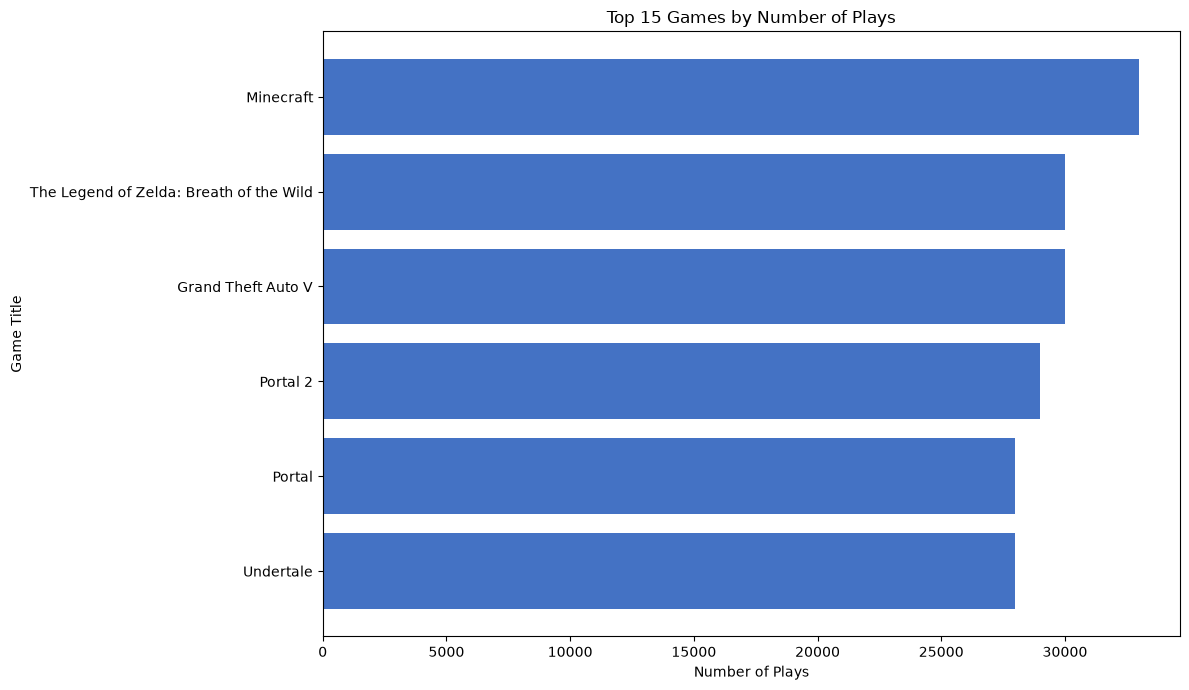

In [27]:
top15 = games.nlargest(15, 'Plays')

plt.figure(figsize=(12, 7))
plt.barh(top15['Title'][::-1], top15['Plays'][::-1])

plt.xlabel('Number of Plays')
plt.ylabel('Game Title')
plt.title('Top 15 Games by Number of Plays')

plt.tight_layout()
plt.show()

### Chart Interpretation — Top Games by Number of Plays

##### 1. Why did you pick this specific chart?
A horizontal bar chart ranks titles by the recorded number of plays and makes the most-engaged titles easy to identify.

##### 2. What insights were found?
Minecraft appears at the top of the engagement dataset by plays, followed by other widely played titles such as The Legend of Zelda: Breath of the Wild and Grand Theft Auto V. The dataset contains repeated records for some titles, so title-level rankings should ideally deduplicate or aggregate titles before drawing final conclusions.

##### 3. Will the gained insights help create a positive business impact?
Play counts can help identify titles with strong engagement signals and provide candidates for deeper retention, community, or franchise analysis.

##### Are there any insights that lead to negative growth? Justify with specific reasons.
High play counts do not directly measure revenue, retention, or satisfaction. Duplicate records can inflate a ranking if not handled consistently, and the data source's audience may not represent all players.


,Title,Rating,Number of Reviews,Team
1252,Elden Ring: Shadow of the Erdtree,4.8,18.0,"['FromSoftware', 'Bandai Namco Entertainment']"
43,Outer Wilds,4.6,1800.0,"['Mobius Digital', 'Annapurna Interactive']"
369,Outer Wilds,4.6,1800.0,"['Mobius Digital', 'Annapurna Interactive']"
819,Outer Wilds,4.6,1800.0,"['Mobius Digital', 'Annapurna Interactive']"
28,Disco Elysium: The Final Cut,4.6,1100.0,['ZA/UM']
139,Disco Elysium,4.6,1100.0,['ZA/UM']
354,Disco Elysium: The Final Cut,4.6,1100.0,['ZA/UM']
428,Disco Elysium,4.6,1100.0,['ZA/UM']
804,Disco Elysium: The Final Cut,4.6,1100.0,['ZA/UM']
894,Disco Elysium,4.6,1100.0,['ZA/UM']


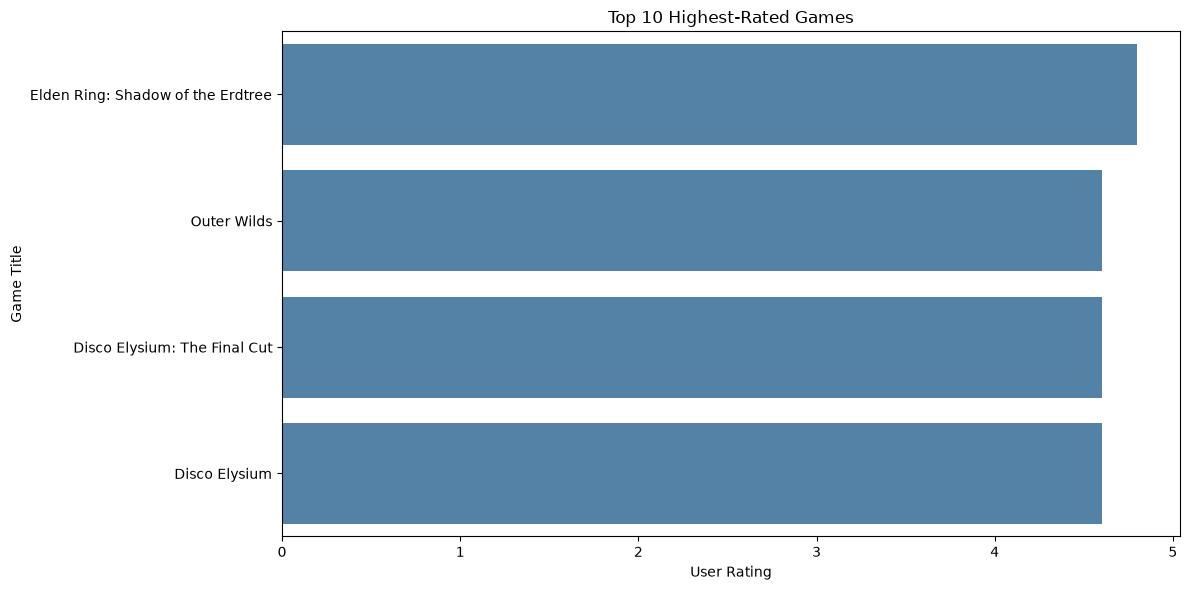

In [28]:
#1. What are the top-rated games by user reviews?
top_rated = games[
    (games['Rating'].notna()) &
    (games['Number of Reviews'].notna())
].sort_values(
    ['Rating', 'Number of Reviews'],
    ascending=[False, False]
).head(10)

display(top_rated[
    ['Title', 'Rating', 'Number of Reviews', 'Team']
])

plt.figure(figsize=(12, 6))
sns.barplot(data=top_rated, x='Rating', y='Title', color='steelblue')
plt.title('Top 10 Highest-Rated Games')
plt.xlabel('User Rating')
plt.ylabel('Game Title')
plt.tight_layout()
plt.show()


### Chart Interpretation — Highest-Rated Games

##### 1. Why did you pick this specific chart?
A horizontal bar chart compares the highest user ratings while displaying each title clearly. Including review counts in the table provides context for how much feedback supports a rating.

##### 2. What insights were found?
The highest observed ratings are around 4.8–4.6 in the dataset. Some highly rated entries have far fewer reviews than others, so a very high rating may be less stable when it is based on a small number of reviews.

##### 3. Will the gained insights help create a positive business impact?
Ratings can help identify titles for qualitative review and understand perceived quality, especially when considered alongside review volume and engagement.

##### Are there any insights that lead to negative growth? Justify with specific reasons.
Ranking games by rating alone may overvalue titles with very few reviews. Ratings can also reflect a particular platform or community. Use a minimum review threshold and additional measures before making product or marketing decisions.


,Team,Average_Rating,Games
290,Konami Computer Entertainment Japan,4.45,4
551,Team Silent,4.34,4
91,Capcom Development Division 1,4.33,3
1,07th Expansion,4.28,3
71,BioWare,4.20,5
545,Team Ico,4.18,3
452,Retro Studios,4.18,5
97,Capcom Production Studio 4,4.18,6
250,IO Interactive,4.16,4
191,FromSoftware,4.15,16


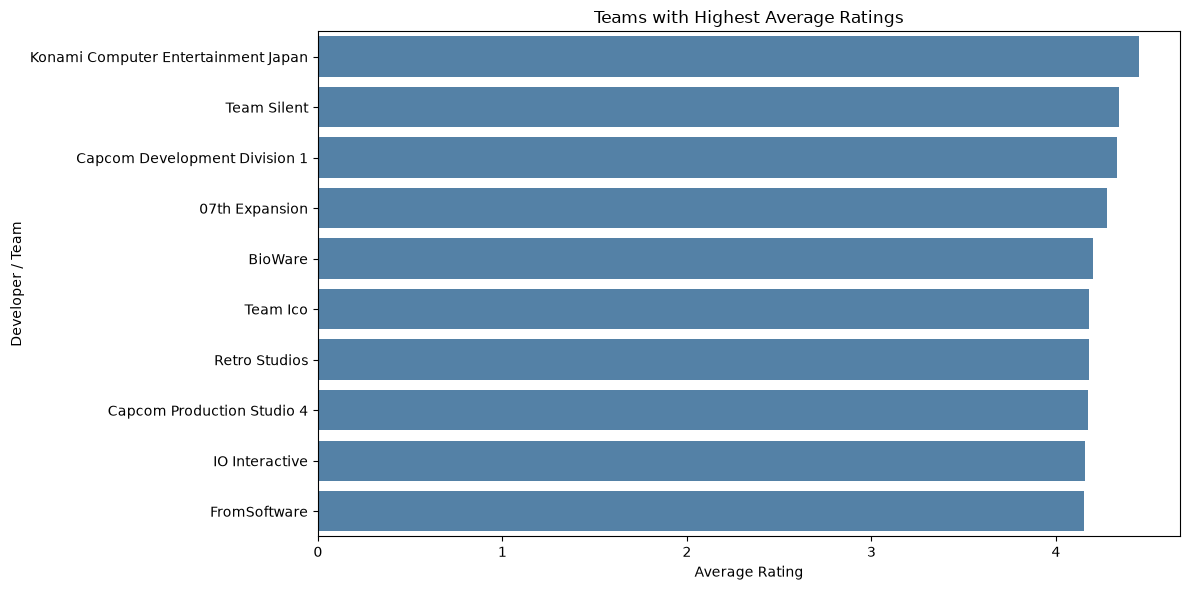

In [29]:
#2. Which developers (Teams) have the highest average ratings
import ast
def parse_list(value):
    if pd.isna(value):
        return []

    if isinstance(value, list):
        return value

    try:
        result = ast.literal_eval(str(value))
        if isinstance(result, list):
            return result
    except (ValueError, SyntaxError):
        pass

    return [str(value).strip()]


team_data = games[['Title', 'Rating', 'Team']].copy()
team_data['Team'] = team_data['Team'].apply(parse_list)
team_data = team_data.explode('Team')

team_data['Team'] = team_data['Team'].astype('string').str.strip()
team_data = team_data[
    team_data['Team'].notna() & (team_data['Team'] != '')
]

team_ratings = team_data.groupby('Team').agg(
    Average_Rating=('Rating', 'mean'),
    Games=('Title', 'nunique')
).reset_index()

# Require at least 3 games to reduce one-game rankings
top_teams = team_ratings[
    team_ratings['Games'] >= 3
].sort_values('Average_Rating', ascending=False).head(10)

display(top_teams.round(2))

plt.figure(figsize=(12, 6))
sns.barplot(data=top_teams, x='Average_Rating', y='Team', color='steelblue')
plt.title('Teams with Highest Average Ratings')
plt.xlabel('Average Rating')
plt.ylabel('Developer / Team')
plt.tight_layout()
plt.show()


### Chart Interpretation — Developer Teams With the Highest Average Ratings

##### 1. Why did you pick this specific chart?
A ranked bar chart of average ratings makes it easier to compare developer teams after splitting multi-team entries into individual team names.

##### 2. What insights were found?
The chart identifies teams with high average ratings among titles represented in this dataset. These results describe the observed catalogue only and may be affected by how many titles each team has and the number of reviews each title receives.

##### 3. Will the gained insights help create a positive business impact?
Team-level ratings can help shortlist studios for further qualitative evaluation or partnership research when combined with delivery history, genre expertise, and commercial performance.

##### Are there any insights that lead to negative growth? Justify with specific reasons.
A studio with one highly rated game may rank above a studio with many consistently good releases. Small sample sizes and multi-developer credits can distort comparisons, so report title counts and consider weighting or minimum sample thresholds.


In [30]:
# Convert Release Date to datetime format
games['Release Date'] = pd.to_datetime(
    games['Release Date'],
    errors='coerce'
)

# Extract the year
games['Release Year'] = games['Release Date'].dt.year

# Check the result
games[['Title', 'Release Date', 'Release Year']].head()

,Title,Release Date,Release Year
0,Elden Ring,2022-02-25,2022.0
1,Hades,2019-12-10,2019.0
2,The Legend of Zelda: Breath of the Wild,2017-03-03,2017.0
3,Undertale,2015-09-15,2015.0
4,Hollow Knight,2017-02-24,2017.0


,Number of Games Released
Release Year,
2004.0,28
2005.0,32
2006.0,26
2007.0,36
2008.0,38
2009.0,29
2010.0,42
2011.0,36
2012.0,45


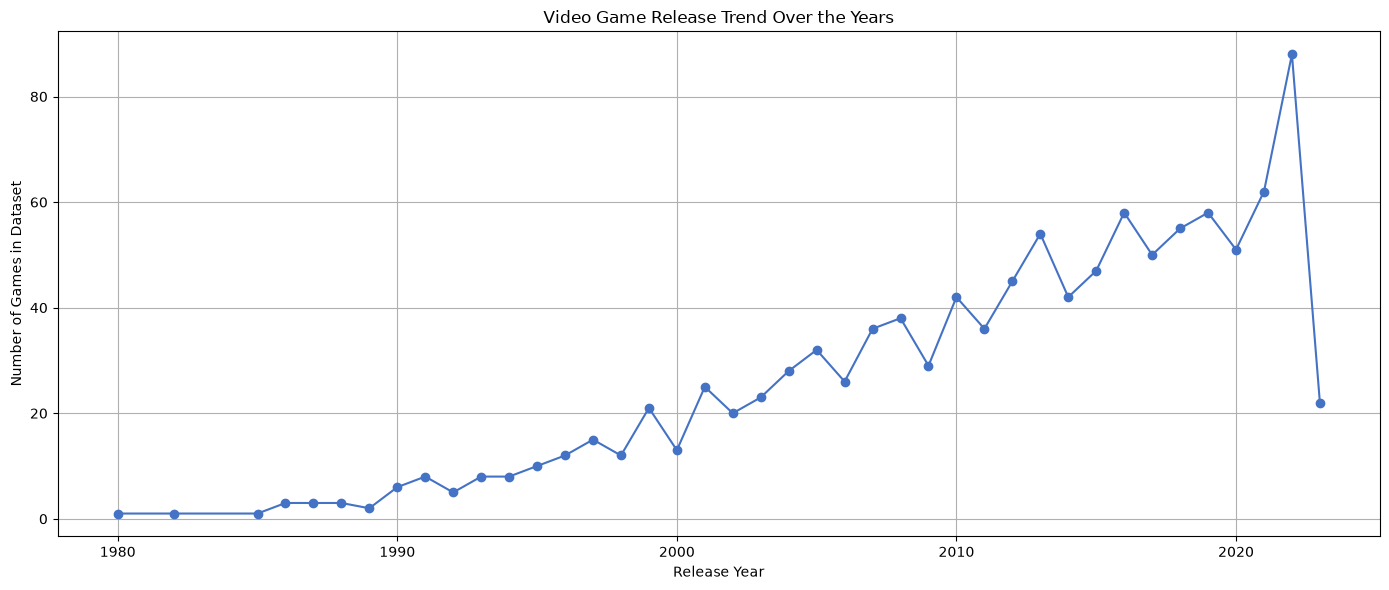

In [31]:
#5. What is the game release trend across years?


yearly_releases = (
    games.dropna(subset=['Release Year'])
    .groupby('Release Year')['Title']
    .nunique()
)

display(yearly_releases.tail(20).rename(
    'Number of Games Released'
).to_frame())

plt.figure(figsize=(14, 6))
yearly_releases.plot(kind='line', marker='o')
plt.title('Video Game Release Trend Over the Years')
plt.xlabel('Release Year')
plt.ylabel('Number of Games in Dataset')
plt.grid(True)
plt.tight_layout()
plt.show()


### Chart Interpretation — Video Game Release Trend Over Time

##### 1. Why did you pick this specific chart?
A line chart is suitable for displaying changes in the number of represented games across release years and helps reveal broad rises or falls over time.

##### 2. What insights were found?
The chart shows how the number of titles in this engagement dataset changes by release year. Because this dataset is a selected catalogue rather than a complete record of every game released, peaks should be interpreted as patterns within the dataset, not as definitive industry-wide release counts.

##### 3. Will the gained insights help create a positive business impact?
Release trends can provide context for catalogue coverage and help identify periods for more detailed market or genre analysis.

##### Are there any insights that lead to negative growth? Justify with specific reasons.
A decline in represented titles could be caused by dataset coverage or missing dates rather than a real industry downturn. Do not use this chart alone to infer market contraction or demand.


Mean rating: 3.72
Median rating: 3.8
Standard deviation: 0.53


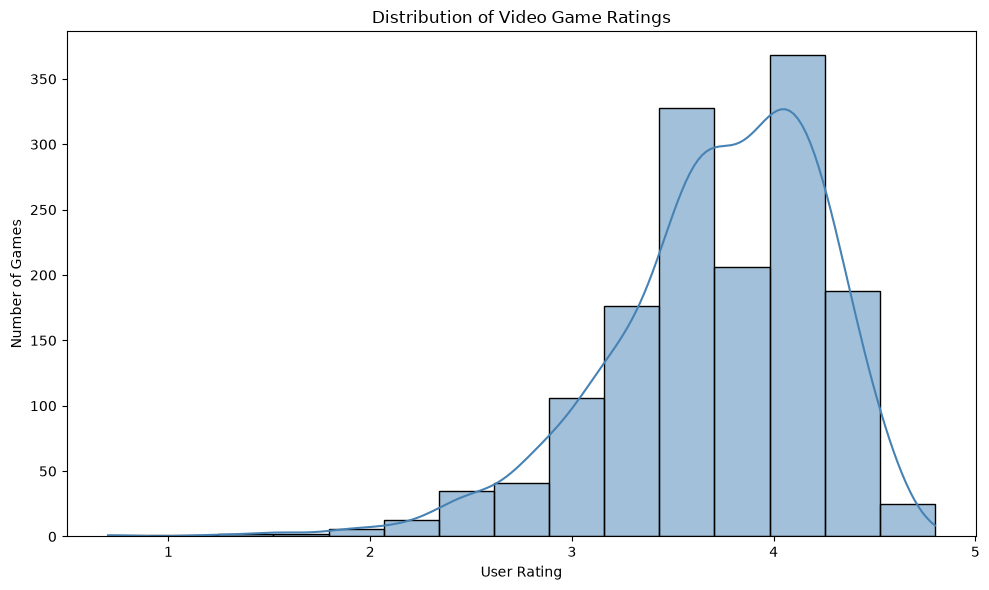

In [32]:
#6. What is the distribution of user ratings?


rating_data = games['Rating'].dropna()

print("Mean rating:", round(rating_data.mean(), 2))
print("Median rating:", round(rating_data.median(), 2))
print("Standard deviation:", round(rating_data.std(), 2))

plt.figure(figsize=(10, 6))
sns.histplot(rating_data, bins=15, kde=True, color='steelblue')
plt.title('Distribution of Video Game Ratings')
plt.xlabel('User Rating')
plt.ylabel('Number of Games')
plt.tight_layout()
plt.show()


### Chart Interpretation — Distribution of User Ratings

##### 1. Why did you pick this specific chart?
A histogram with a density curve shows the spread, concentration, and shape of numeric ratings; the mean and median summarize the central tendency.

##### 2. What insights were found?
For the engagement dataset, the average rating is approximately 3.72 and the median is 3.80. The distribution shows how ratings are spread across the recorded titles, but the pattern applies only to games with non-missing ratings.

##### 3. Will the gained insights help create a positive business impact?
The distribution provides a baseline for comparing ratings across genres, studios, or release periods and can help identify unusually high or low scores for further review.

##### Are there any insights that lead to negative growth? Justify with specific reasons.
Averages can hide differences between genres and can be biased if unrated titles are excluded. Ratings are subjective and should not be treated as a direct measure of sales, retention, or profitability.


,Title,Wishlist,Rating,Plays
0,Elden Ring,4800.0,4.5,17000.0
776,Elden Ring,4800.0,4.5,17000.0
326,Elden Ring,4800.0,4.5,17000.0
782,Omori,3800.0,4.2,7200.0
332,Omori,3800.0,4.2,7200.0
6,Omori,3800.0,4.2,7200.0
357,NieR Replicant ver.1.22474487139...,3700.0,4.2,6700.0
807,NieR Replicant ver.1.22474487139...,3700.0,4.2,6700.0
31,NieR Replicant ver.1.22474487139...,3700.0,4.2,6700.0
1,Hades,3600.0,4.3,21000.0


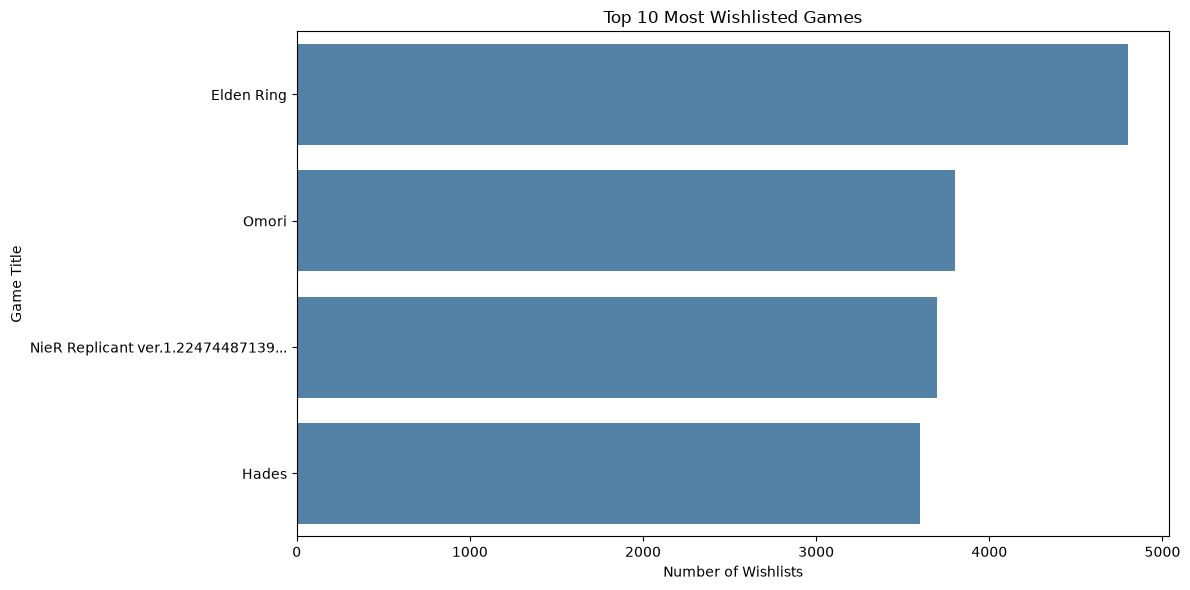

In [33]:
#7. What are the top 10 most wishlisted games?


top_wishlisted = games.sort_values(
    'Wishlist', ascending=False
).head(10)

display(top_wishlisted[['Title', 'Wishlist', 'Rating', 'Plays']])

plt.figure(figsize=(12, 6))
sns.barplot(data=top_wishlisted, x='Wishlist', y='Title', color='steelblue')
plt.title('Top 10 Most Wishlisted Games')
plt.xlabel('Number of Wishlists')
plt.ylabel('Game Title')
plt.tight_layout()
plt.show()


### Chart Interpretation — Most Wishlisted Games

##### 1. Why did you pick this specific chart?
A horizontal bar chart ranks games by wishlist count and makes relative interest easy to compare.

##### 2. What insights were found?
The Legend of Zelda: Tears of the Kingdom and Elden Ring are among the most wishlisted entries in this dataset. Repeated records for the same title can appear, so a final title ranking should deduplicate or aggregate entries consistently.

##### 3. Will the gained insights help create a positive business impact?
Wishlists can serve as an indicator of expressed interest and may help prioritize launch communications or investigate potential demand.

##### Are there any insights that lead to negative growth? Justify with specific reasons.
A wishlist does not guarantee a purchase or active play. Treating wishlist counts as forecast sales may overstate demand; conversion rates, release timing, and platform coverage would be needed for stronger predictions.


,Average Plays
Genres,
MOBA,10166.67
Shooter,7565.73
Racing,7197.00
Platform,7162.52
Turn Based Strategy,6834.18
Adventure,6591.59
Brawler,6518.27
RPG,6381.21
Sport,5977.32


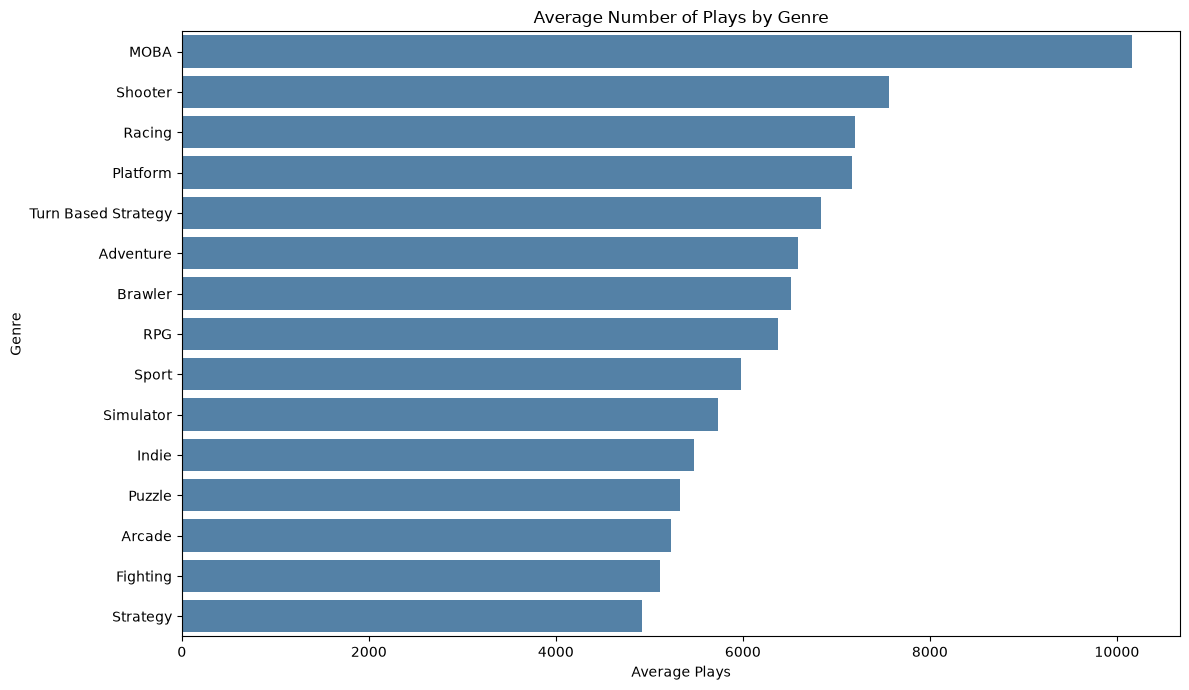

In [34]:
#8. What is the average number of plays per genre?


plays_by_genre = games[['Title', 'Genres', 'Plays']].copy()
plays_by_genre['Genres'] = plays_by_genre['Genres'].apply(parse_list)
plays_by_genre = plays_by_genre.explode('Genres')

plays_by_genre['Genres'] = (
    plays_by_genre['Genres'].astype('string').str.strip()
)

plays_by_genre = plays_by_genre.dropna(
    subset=['Genres', 'Plays']
)

average_plays = (
    plays_by_genre.groupby('Genres')['Plays']
    .mean()
    .sort_values(ascending=False)
)

display(average_plays.round(2).rename(
    'Average Plays'
).to_frame())

plt.figure(figsize=(12, 7))
sns.barplot(
    x=average_plays.head(15).values,
    y=average_plays.head(15).index,
    color='steelblue'
)
plt.title('Average Number of Plays by Genre')
plt.xlabel('Average Plays')
plt.ylabel('Genre')
plt.tight_layout()
plt.show()


### Chart Interpretation — Average Plays by Genre

##### 1. Why did you pick this specific chart?
A genre-level bar chart allows the mean play count to be compared across genres after splitting multi-genre labels so a game can contribute to each genre it is tagged with.

##### 2. What insights were found?
The chart compares average recorded plays among genres. Genres with high averages may contain a few exceptionally popular titles, so the mean should be considered alongside the number of games and a median or distribution view.

##### 3. Will the gained insights help create a positive business impact?
Genre-level engagement can help teams choose categories for deeper user research, community analysis, or catalogue promotion.

##### Are there any insights that lead to negative growth? Justify with specific reasons.
Average plays can be skewed by blockbuster titles and multi-genre tagging. It does not measure per-player engagement or profitability, so it should not be used as the sole basis for genre investment.


Most Productive Teams


,Team,Games,Total_Plays,Average_Rating
376,Nintendo,169,1868428.0,3.80
90,Capcom,62,488173.0,3.77
515,Square Enix,57,395932.0,3.84
484,Sega,44,333530.0,3.51
167,Electronic Arts,41,470267.0,3.63
289,Konami,31,221894.0,3.88
23,Activision,30,251400.0,3.54
55,Bandai Namco Entertainment,27,323330.0,3.75
590,Ubisoft Entertainment,27,215956.0,3.40
506,Sony Interactive Entertainment,24,363300.0,4.01


Teams with the Highest Total Plays


,Team,Games,Total_Plays,Average_Rating
376,Nintendo,169,1868428.0,3.80
90,Capcom,62,488173.0,3.77
167,Electronic Arts,41,470267.0,3.63
378,Nintendo EAD,21,465840.0,3.88
515,Square Enix,57,395932.0,3.84
506,Sony Interactive Entertainment,24,363300.0,4.01
603,Valve,12,335000.0,4.00
484,Sega,44,333530.0,3.51
55,Bandai Namco Entertainment,27,323330.0,3.75
191,FromSoftware,16,307950.0,4.15


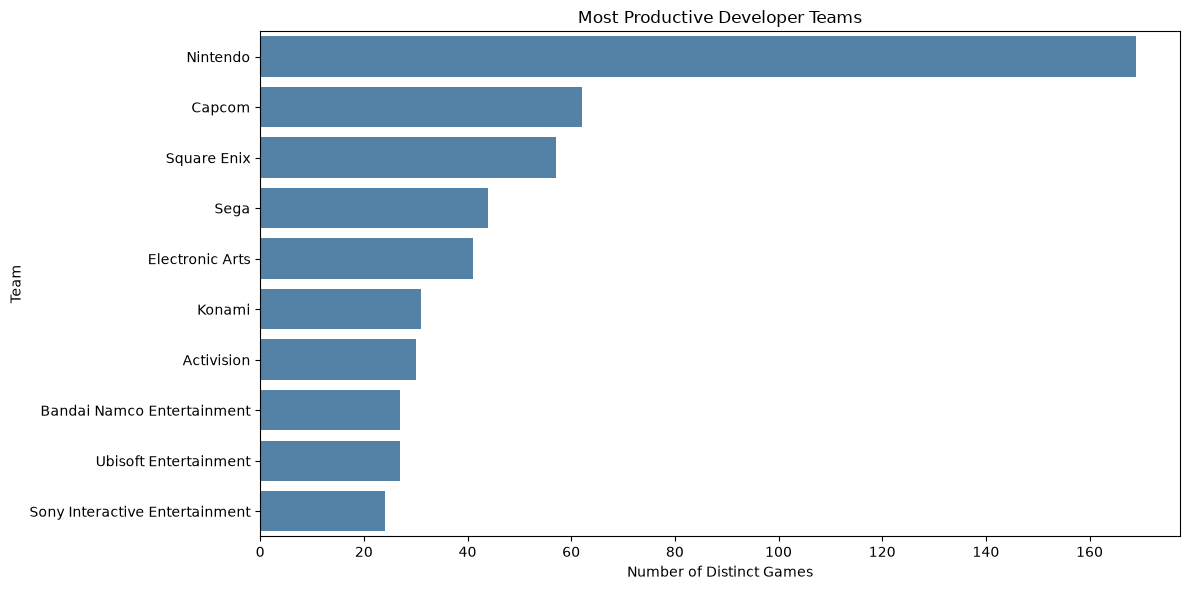

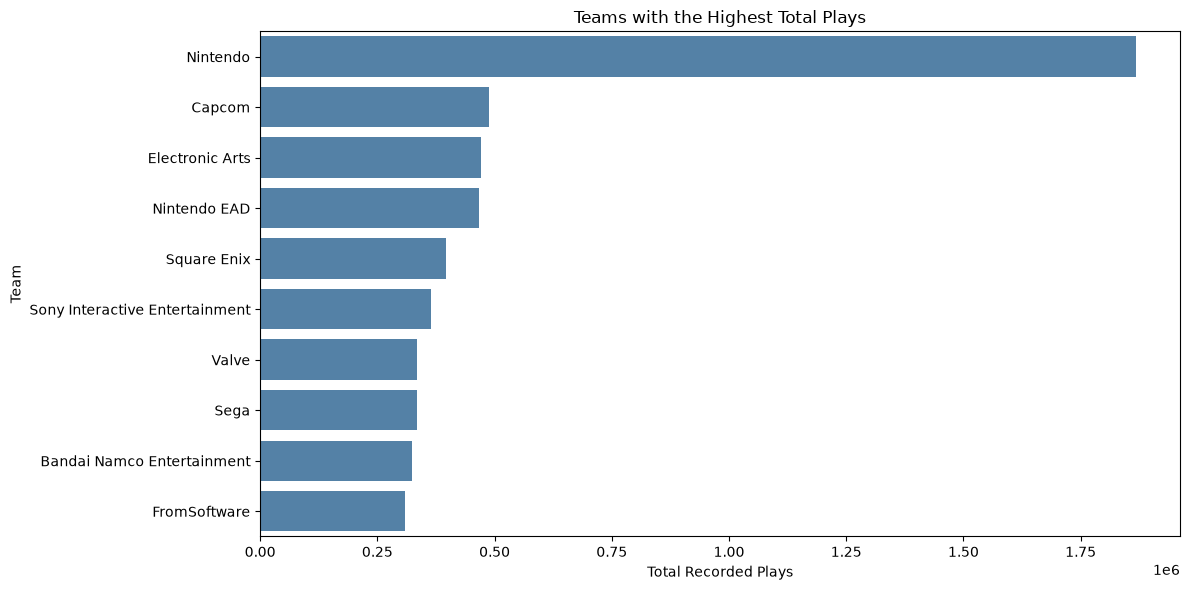

In [35]:
#9. Which developer studios are the most productive and impactful?


studio_data = games[['Title', 'Team', 'Plays', 'Rating']].copy()
studio_data['Team'] = studio_data['Team'].apply(parse_list)
studio_data = studio_data.explode('Team')

studio_data['Team'] = studio_data['Team'].astype('string').str.strip()
studio_data = studio_data[
    studio_data['Team'].notna() & (studio_data['Team'] != '')
]

studio_summary = studio_data.groupby('Team').agg(
    Games=('Title', 'nunique'),
    Total_Plays=('Plays', 'sum'),
    Average_Rating=('Rating', 'mean')
).reset_index()

# Require at least 3 distinct games
studio_summary = studio_summary[studio_summary['Games'] >= 3]

# Rank by productivity
most_productive = studio_summary.sort_values(
    'Games', ascending=False
).head(10)

# Rank by total recorded plays
most_impactful = studio_summary.sort_values(
    'Total_Plays', ascending=False
).head(10)

print("Most Productive Teams")
display(most_productive.round(2))

print("Teams with the Highest Total Plays")
display(most_impactful.round(2))

plt.figure(figsize=(12, 6))
sns.barplot(data=most_productive, x='Games', y='Team', color='steelblue')
plt.title('Most Productive Developer Teams')
plt.xlabel('Number of Distinct Games')
plt.ylabel('Team')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
sns.barplot(data=most_impactful, x='Total_Plays', y='Team', color='steelblue')
plt.title('Teams with the Highest Total Plays')
plt.xlabel('Total Recorded Plays')
plt.ylabel('Team')
plt.tight_layout()
plt.show()


### Chart Interpretation — Productive and Impactful Developer Studios

##### 1. Why did you pick this specific chart?
The analysis combines number of games, total plays, and average rating to give a broader view of studio output and observed engagement rather than relying on a single metric.

##### 2. What insights were found?
The chart/table highlights studios that have multiple titles, high cumulative plays, and/or strong average ratings. These dimensions may produce different rankings, because productivity and audience response are not the same thing.

##### 3. Will the gained insights help create a positive business impact?
The combined measures can help shortlist studios for further review and distinguish high output from high engagement. They can also inform questions for a more detailed portfolio comparison.

##### Are there any insights that lead to negative growth? Justify with specific reasons.
Total plays naturally favour studios with more titles, while average ratings may be unstable for studios with few titles. The analysis lacks development budgets, release dates, and profit, so it cannot establish studio efficiency or financial impact.


Final assignment summary
Question	Analysis method
1. Top-rated games	Rating and number of reviews
2. Highest-rated teams	Average rating by team
3. Common genres	Genre frequency
4. Backlog vs. wishlist	Backlog-to-wishlist ratio
5. Release trend	Games released per year
6. Rating distribution	Histogram, mean and median
7. Most wishlisted games	Wishlist ranking
8. Average plays by genre	Grouped mean
9. Productive and impactful studios	Game count, total plays and average rating

In [36]:

import re

sns.set_theme(style="whitegrid")

# Create working copies of the existing DataFrames
sales_data = data.copy()
games_data = games.copy()

print("VGSales dataset:", sales_data.shape)
print("Games dataset:", games_data.shape)

print("VGSales columns:", sales_data.columns.tolist())
print("Games columns:", games_data.columns.tolist())


VGSales dataset: (16540, 11)
Games dataset: (1498, 14)
VGSales columns: ['Rank', 'Name', 'Platform', 'Year', 'Genre', 'Publisher', 'NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales']
Games columns: ['Title', 'Release Date', 'Team', 'Rating', 'Times Listed', 'Number of Reviews', 'Genres', 'Summary', 'Reviews', 'Plays', 'Playing', 'Backlogs', 'Wishlist', 'Release Year']


In [37]:

# Standardize titles for matching
def clean_title(title):
    if pd.isna(title):
        return np.nan

    title = str(title).lower().strip()
    title = re.sub(r"[^a-z0-9]+", " ", title)
    return re.sub(r"\s+", " ", title).strip()

sales_data["Merge_Title"] = sales_data["Name"].apply(clean_title)
games_data["Merge_Title"] = games_data["Title"].apply(clean_title)

# Convert abbreviated values such as 3.9K and 1.2M
def convert_number(value):
    if pd.isna(value):
        return np.nan

    if isinstance(value, (int, float, np.number)):
        return float(value)

    value = str(value).strip().replace(",", "")

    if value.upper().endswith("K"):
        return float(value[:-1]) * 1000
    elif value.upper().endswith("M"):
        return float(value[:-1]) * 1000000

    try:
        return float(value)
    except ValueError:
        return np.nan

numeric_columns = [
    "Rating", "Times Listed", "Number of Reviews",
    "Plays", "Playing", "Backlogs", "Wishlist"
]

for col in numeric_columns:
    if col in games_data.columns:
        games_data[col] = games_data[col].apply(convert_number)

games_data["Release Date"] = pd.to_datetime(
    games_data["Release Date"], errors="coerce"
)

print("Title preparation completed.")


Title preparation completed.


In [38]:

# Check duplicate engagement titles
print(
    "Duplicate titles in games:",
    games_data["Merge_Title"].duplicated().sum()
)

# Keep one record per title for the initial merge
games_unique = games_data.drop_duplicates(
    subset="Merge_Title",
    keep="first"
)

# Merge sales data with engagement data
merged = sales_data.merge(
    games_unique,
    on="Merge_Title",
    how="left",
    indicator=True,
    validate="many_to_one"
)

# Create a consistent release-year column
merged["Release Year"] = pd.to_numeric(
    merged["Year"], errors="coerce"
)

merged["Release Year"] = merged["Release Year"].fillna(
    pd.to_datetime(
        merged["Release Date"], errors="coerce"
    ).dt.year
)

print("Merged dataset shape:", merged.shape)
print("\nMatch results:")
print(merged["_merge"].value_counts())

display(merged.head())


Duplicate titles in games: 414
Merged dataset shape: (16540, 27)

Match results:
_merge
left_only     15516
both           1024
right_only        0
Name: count, dtype: int64


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,...,Number of Reviews,Genres,Summary,Reviews,Plays,Playing,Backlogs,Wishlist,Release Year,_merge
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,...,775.0,"['Simulator', 'Sport']",Bowl like a pro or go for that home run...\n ...,"[""The perfect arcade game. Another type of gam...",18000.0,39.0,320.0,93.0,2006.0,both
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,...,1500.0,"['Adventure', 'Platform']",A side scrolling 2D platformer and first entry...,"[""I actually had no idea this game was so long...",18000.0,59.0,733.0,237.0,1985.0,both
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,...,1000.0,['Racing'],Mario Kart Wii is a multiplayer-oriented racin...,"[""Completed to fulfill a childhood dream and i...",19000.0,88.0,461.0,168.0,2008.0,both
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2009.0,left_only
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1996.0,left_only


In [39]:
# Check merge quality
matched = (merged["_merge"] == "both").sum()
unmatched = (merged["_merge"] == "left_only").sum()

print("Original VGSales rows:", len(data))
print("Merged rows:", len(merged))
print("Matched rows:", matched)
print("Unmatched rows:", unmatched)
print("Match percentage:", round(matched / len(data) * 100, 2), "%")

# Inspect matched examples
display(
    merged.loc[
        merged["_merge"] == "both",
        ["Name", "Title", "Platform", "Genre", "Rating",
         "Global_Sales", "Plays", "Wishlist"]
    ].head(10)
)

# Inspect unmatched examples
display(
    merged.loc[
        merged["_merge"] == "left_only",
        ["Name", "Platform", "Genre", "Global_Sales"]
    ].head(10)
)

Original VGSales rows: 16540
Merged rows: 16540
Matched rows: 1024
Unmatched rows: 15516
Match percentage: 6.19 %


,Name,Title,Platform,Genre,Rating,Global_Sales,Plays,Wishlist
0,Wii Sports,Wii Sports,Wii,Sports,3.7,82.74,18000.0,93.0
1,Super Mario Bros.,Super Mario Bros.,NES,Platform,3.5,40.24,18000.0,237.0
2,Mario Kart Wii,Mario Kart Wii,Wii,Racing,3.9,35.82,19000.0,168.0
5,Tetris,Tetris,GB,Puzzle,4.1,30.26,9600.0,66.0
6,New Super Mario Bros.,New Super Mario Bros.,DS,Platform,3.5,30.01,16000.0,287.0
8,New Super Mario Bros. Wii,New Super Mario Bros. Wii,Wii,Platform,3.5,28.62,13000.0,241.0
11,Mario Kart DS,Mario Kart DS,DS,Racing,3.8,23.42,15000.0,159.0
16,Grand Theft Auto V,Grand Theft Auto V,PS3,Action,3.8,21.40,30000.0,664.0
17,Grand Theft Auto: San Andreas,Grand Theft Auto: San Andreas,PS2,Action,4.1,20.81,19000.0,742.0
18,Super Mario World,Super Mario World,SNES,Platform,4.2,20.61,18000.0,460.0


,Name,Platform,Genre,Global_Sales
3,Wii Sports Resort,Wii,Sports,33.00
4,Pokemon Red/Pokemon Blue,GB,Role-Playing,31.37
7,Wii Play,Wii,Misc,29.02
9,Duck Hunt,NES,Shooter,28.31
10,Nintendogs,DS,Simulation,24.76
12,Pokemon Gold/Pokemon Silver,GB,Role-Playing,23.10
13,Wii Fit,Wii,Sports,22.72
14,Wii Fit Plus,Wii,Sports,22.00
15,Kinect Adventures!,X360,Misc,21.82
19,Brain Age: Train Your Brain in Minutes a Day,DS,Misc,20.22


In [40]:

# Check merge quality
matched = (merged["_merge"] == "both").sum()
unmatched = (merged["_merge"] == "left_only").sum()

print("Original VGSales rows:", len(data))
print("Merged rows:", len(merged))
print("Matched rows:", matched)
print("Unmatched rows:", unmatched)
print("Match percentage:", round(matched / len(data) * 100, 2), "%")

# Display matched records
display(
    merged.loc[
        merged["_merge"] == "both",
        ["Name", "Platform", "Genre", "Rating",
         "Global_Sales", "Plays", "Wishlist"]
    ].head(10)
)

# Display unmatched records
display(
    merged.loc[
        merged["_merge"] == "left_only",
        ["Name", "Platform", "Genre", "Global_Sales"]
    ].head(10)
)


Original VGSales rows: 16540
Merged rows: 16540
Matched rows: 1024
Unmatched rows: 15516
Match percentage: 6.19 %


,Name,Platform,Genre,Rating,Global_Sales,Plays,Wishlist
0,Wii Sports,Wii,Sports,3.7,82.74,18000.0,93.0
1,Super Mario Bros.,NES,Platform,3.5,40.24,18000.0,237.0
2,Mario Kart Wii,Wii,Racing,3.9,35.82,19000.0,168.0
5,Tetris,GB,Puzzle,4.1,30.26,9600.0,66.0
6,New Super Mario Bros.,DS,Platform,3.5,30.01,16000.0,287.0
8,New Super Mario Bros. Wii,Wii,Platform,3.5,28.62,13000.0,241.0
11,Mario Kart DS,DS,Racing,3.8,23.42,15000.0,159.0
16,Grand Theft Auto V,PS3,Action,3.8,21.40,30000.0,664.0
17,Grand Theft Auto: San Andreas,PS2,Action,4.1,20.81,19000.0,742.0
18,Super Mario World,SNES,Platform,4.2,20.61,18000.0,460.0


,Name,Platform,Genre,Global_Sales
3,Wii Sports Resort,Wii,Sports,33.00
4,Pokemon Red/Pokemon Blue,GB,Role-Playing,31.37
7,Wii Play,Wii,Misc,29.02
9,Duck Hunt,NES,Shooter,28.31
10,Nintendogs,DS,Simulation,24.76
12,Pokemon Gold/Pokemon Silver,GB,Role-Playing,23.10
13,Wii Fit,Wii,Sports,22.72
14,Wii Fit Plus,Wii,Sports,22.00
15,Kinect Adventures!,X360,Misc,21.82
19,Brain Age: Train Your Brain in Minutes a Day,DS,Misc,20.22


In [41]:
import pandas as pd
import numpy as np
import re

# Create working copies
sales = data.copy()
games_data = games.copy()

# Standardize game titles for matching
def clean_title(title):
    if pd.isna(title):
        return np.nan

    title = str(title).lower().strip()
    title = re.sub(r"[^a-z0-9]+", " ", title)
    title = re.sub(r"\s+", " ", title).strip()

    return title

sales["Merge_Title"] = sales["Name"].apply(clean_title)
games_data["Merge_Title"] = games_data["Title"].apply(clean_title)

# Convert engagement columns to numeric values
def convert_number(value):
    if pd.isna(value):
        return np.nan

    if isinstance(value, (int, float, np.number)):
        return float(value)

    value = str(value).strip().replace(",", "")

    if value.upper().endswith("K"):
        return float(value[:-1]) * 1000
    elif value.upper().endswith("M"):
        return float(value[:-1]) * 1000000

    try:
        return float(value)
    except ValueError:
        return np.nan

numeric_columns = [
    "Rating", "Times Listed", "Number of Reviews",
    "Plays", "Playing", "Backlogs", "Wishlist"
]

for col in numeric_columns:
    if col in games_data.columns:
        games_data[col] = games_data[col].apply(convert_number)

# Keep one Games record per standardized title
games_unique = games_data.drop_duplicates(
    subset="Merge_Title",
    keep="first"
)

# Match sales Name with Games Title
merged = sales.merge(
    games_unique,
    on="Merge_Title",
    how="inner",
    validate="many_to_one",
    suffixes=("_sales", "_games")
)

# Check matching results
print("Original VGSales rows:", len(sales))
print("Original Games rows:", len(games_data))
print("Merged rows:", len(merged))
print("Unique matched game titles:", merged["Merge_Title"].nunique())

display(merged.head())

Original VGSales rows: 16540
Original Games rows: 1498
Merged rows: 1024
Unique matched game titles: 487


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,...,Times Listed,Number of Reviews,Genres,Summary,Reviews,Plays,Playing,Backlogs,Wishlist,Release Year
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,...,775.0,775.0,"['Simulator', 'Sport']",Bowl like a pro or go for that home run...\n ...,"[""The perfect arcade game. Another type of gam...",18000.0,39.0,320.0,93.0,2006.0
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,...,1500.0,1500.0,"['Adventure', 'Platform']",A side scrolling 2D platformer and first entry...,"[""I actually had no idea this game was so long...",18000.0,59.0,733.0,237.0,1985.0
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,...,1000.0,1000.0,['Racing'],Mario Kart Wii is a multiplayer-oriented racin...,"[""Completed to fulfill a childhood dream and i...",19000.0,88.0,461.0,168.0,2008.0
3,6,Tetris,GB,1989.0,Puzzle,Nintendo,23.20,2.26,4.22,0.58,...,688.0,688.0,"['Arcade', 'Puzzle']",Tetris is a tile-matching puzzle video game. T...,"['Fucking love Tetris. Timeless game.', 'A gre...",9600.0,54.0,175.0,66.0,1989.0
4,7,New Super Mario Bros.,DS,2006.0,Platform,Nintendo,11.38,9.23,6.50,2.90,...,991.0,991.0,"['Adventure', 'Platform']",New Super Mario Bros. is a side-scrolling 2.5D...,['Fun game with fun power ups. I just wish the...,16000.0,108.0,824.0,287.0,2006.0


In [42]:
print("Missing values in merged dataset:")
display(merged.isnull().sum())

print("Number of unique matched titles:",
      merged["Merge_Title"].nunique())

print("Games matched by platform:")
display(
    merged.groupby("Platform")["Merge_Title"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

Missing values in merged dataset:


Rank                 0
Name                 0
Platform             0
Year                 0
Genre                0
Publisher            0
NA_Sales             0
EU_Sales             0
JP_Sales             0
Other_Sales          0
Global_Sales         0
Merge_Title          0
Title                0
Release Date         0
Team                 0
Rating               0
Times Listed         0
Number of Reviews    0
Genres               0
Summary              0
Reviews              0
Plays                0
Playing              0
Backlogs             0
Wishlist             0
Release Year         0
dtype: int64

Number of unique matched titles: 487
Games matched by platform:


Platform
PS3     154
X360    142
PC      128
PS2      79
PS4      62
XOne     48
Wii      42
DS       42
PS       41
3DS      34
Name: Merge_Title, dtype: int64

In [43]:
# Save the merged dataset as a CSV file
merged.to_csv("Merged_VGSales_Games.csv", index=False, encoding="utf-8-sig")

print("Dataset exported successfully!")
print("Rows:", merged.shape[0])
print("Columns:", merged.shape[1])
print("File: Merged_VGSales_Games.csv")

Dataset exported successfully!
Rows: 1024
Columns: 26
File: Merged_VGSales_Games.csv


In [44]:

# Step 1: Basic overview of the merged dataset
sns.set_theme(style="whitegrid")

print("Dataset shape:", merged.shape)
print("Number of unique games:", merged["Merge_Title"].nunique())

print("\nColumn names:")
print(merged.columns.tolist())

print("\nData types:")
print(merged.dtypes)

print("\nFirst five rows:")
display(merged.head())

print("\nStatistical summary:")
display(merged.describe(include="all").T)



Dataset shape: (1024, 26)
Number of unique games: 487

Column names:
['Rank', 'Name', 'Platform', 'Year', 'Genre', 'Publisher', 'NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales', 'Merge_Title', 'Title', 'Release Date', 'Team', 'Rating', 'Times Listed', 'Number of Reviews', 'Genres', 'Summary', 'Reviews', 'Plays', 'Playing', 'Backlogs', 'Wishlist', 'Release Year']

Data types:
Rank                          int64
Name                            str
Platform                        str
Year                        float64
Genre                           str
Publisher                       str
NA_Sales                    float64
EU_Sales                    float64
JP_Sales                    float64
Other_Sales                 float64
Global_Sales                float64
Merge_Title                     str
Title                           str
Release Date         datetime64[us]
Team                            str
Rating                      float64
Times Listed                f

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,...,Times Listed,Number of Reviews,Genres,Summary,Reviews,Plays,Playing,Backlogs,Wishlist,Release Year
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,...,775.0,775.0,"['Simulator', 'Sport']",Bowl like a pro or go for that home run...\n ...,"[""The perfect arcade game. Another type of gam...",18000.0,39.0,320.0,93.0,2006.0
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,...,1500.0,1500.0,"['Adventure', 'Platform']",A side scrolling 2D platformer and first entry...,"[""I actually had no idea this game was so long...",18000.0,59.0,733.0,237.0,1985.0
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,...,1000.0,1000.0,['Racing'],Mario Kart Wii is a multiplayer-oriented racin...,"[""Completed to fulfill a childhood dream and i...",19000.0,88.0,461.0,168.0,2008.0
3,6,Tetris,GB,1989.0,Puzzle,Nintendo,23.20,2.26,4.22,0.58,...,688.0,688.0,"['Arcade', 'Puzzle']",Tetris is a tile-matching puzzle video game. T...,"['Fucking love Tetris. Timeless game.', 'A gre...",9600.0,54.0,175.0,66.0,1989.0
4,7,New Super Mario Bros.,DS,2006.0,Platform,Nintendo,11.38,9.23,6.50,2.90,...,991.0,991.0,"['Adventure', 'Platform']",New Super Mario Bros. is a side-scrolling 2.5D...,['Fun game with fun power ups. I just wish the...,16000.0,108.0,824.0,287.0,2006.0



Statistical summary:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Rank,1024.0,NaN,NaN,NaN,3945.280273,1.0,734.75,2231.5,5786.5,16565.0,4192.619488
Name,1024,488,FIFA 14,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Platform,1024,25,PS3,154,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,1024.0,NaN,NaN,NaN,2008.055664,1981.0,2005.0,2010.0,2013.0,2016.0,6.343524
Genre,1024,12,Action,349,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Publisher,1024,62,Nintendo,112,NaN,NaN,NaN,NaN,NaN,NaN,NaN
NA_Sales,1024.0,NaN,NaN,NaN,1.04082,0.0,0.12,0.42,1.0525,41.49,2.341539
EU_Sales,1024.0,NaN,NaN,NaN,0.620889,0.0,0.06,0.25,0.6325,29.02,1.365989
JP_Sales,1024.0,NaN,NaN,NaN,0.227373,0.0,0.0,0.02,0.14,6.81,0.621234
Other_Sales,1024.0,NaN,NaN,NaN,0.20752,0.0,0.02,0.07,0.21,10.57,0.542403


In [45]:

# Step 2: Data quality checks

print("Missing values in each column:")
display(merged.isnull().sum())

print("Total missing values:", merged.isnull().sum().sum())

print("Exact duplicate rows:", merged.duplicated().sum())

print("Duplicate game-platform combinations:",
      merged.duplicated(subset=["Merge_Title", "Platform"]).sum())


Missing values in each column:


Rank                 0
Name                 0
Platform             0
Year                 0
Genre                0
Publisher            0
NA_Sales             0
EU_Sales             0
JP_Sales             0
Other_Sales          0
Global_Sales         0
Merge_Title          0
Title                0
Release Date         0
Team                 0
Rating               0
Times Listed         0
Number of Reviews    0
Genres               0
Summary              0
Reviews              0
Plays                0
Playing              0
Backlogs             0
Wishlist             0
Release Year         0
dtype: int64

Total missing values: 0
Exact duplicate rows: 0
Duplicate game-platform combinations: 0


,Genre,Total_Global_Sales,Number_of_Records
0,Action,1750.33,3309
10,Sports,1329.35,2343
8,Shooter,1037.32,1308
7,Role-Playing,927.31,1486
4,Platform,830.87,884
3,Misc,802.15,1712
6,Racing,732.03,1248
2,Fighting,445.70,846
9,Simulation,391.96,863
5,Puzzle,244.94,581


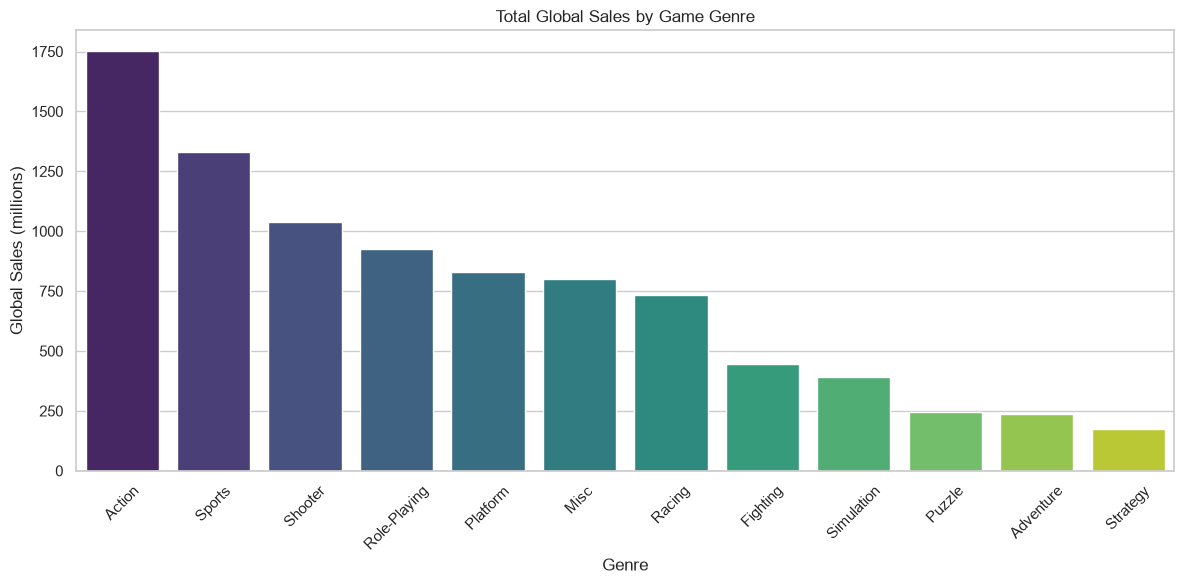

Top genre: Action
Total global sales: 1750.33 million


In [46]:

# Question 21: Global sales by genre

genre_sales = (
    sales.groupby("Genre", as_index=False)
    .agg(
        Total_Global_Sales=("Global_Sales", "sum"),
        Number_of_Records=("Name", "count")
    )
    .sort_values("Total_Global_Sales", ascending=False)
)

display(genre_sales)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=genre_sales,
    x="Genre",
    y="Total_Global_Sales",
    hue="Genre",
    palette="viridis",
    legend=False
)

plt.title("Total Global Sales by Game Genre")
plt.xlabel("Genre")
plt.ylabel("Global Sales (millions)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

top_genre = genre_sales.iloc[0]

print("Top genre:", top_genre["Genre"])
print("Total global sales:",
      round(top_genre["Total_Global_Sales"], 2), "million")


### Chart Interpretation — Global Sales by Genre

##### 1. Why did you pick this specific chart?
A bar chart is effective for comparing cumulative global sales across discrete genre categories and makes the highest- and lowest-sales genres easy to rank.

##### 2. What insights were found?
Action leads the historical sales dataset at approximately 1,750 million units, followed by Sports and Shooter. Strategy and Adventure have the lowest cumulative totals among the listed genres.

##### 3. Will the gained insights help create a positive business impact?
The ranking can help prioritize follow-up research into genre demand, franchise mix, and sales per title.

##### Are there any insights that lead to negative growth? Justify with specific reasons.
Total sales are affected by the number of games in each genre and do not show profit margins. Underinvesting in smaller genres based only on totals could overlook successful niche audiences.


Unique matched games: 487
Rating-sales correlation: 0.014


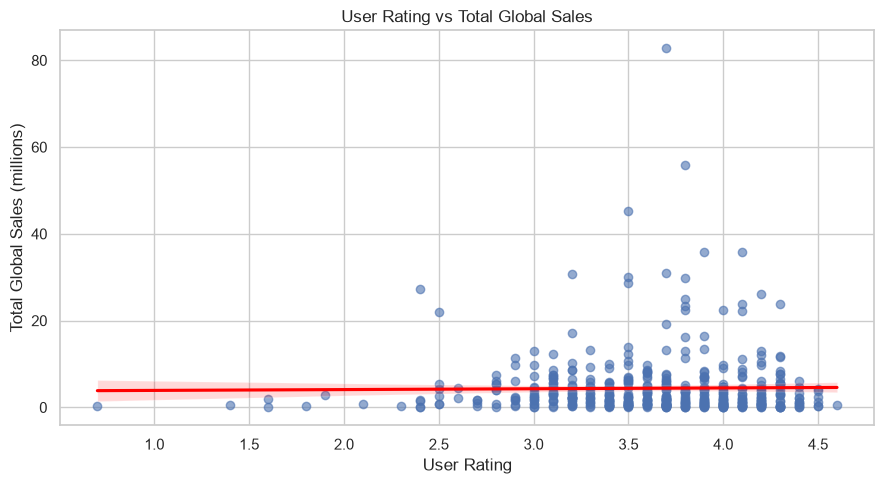

In [47]:
# Question 22: User rating vs global sales

sales_by_game = (
    sales.groupby("Merge_Title", as_index=False)
    .agg(
        Name=("Name", "first"),
        Total_Global_Sales=("Global_Sales", "sum"),
        Genre=("Genre", "first"),
        Platform_Count=("Platform", "nunique")
    )
)

games_unique = games_data.drop_duplicates(
    subset="Merge_Title",
    keep="first"
)

merged_by_game = sales_by_game.merge(
    games_unique,
    on="Merge_Title",
    how="inner",
    validate="one_to_one",
    suffixes=("_sales", "_games")
)

rating_sales = merged_by_game.dropna(
    subset=["Rating", "Total_Global_Sales"]
)

correlation = rating_sales["Rating"].corr(
    rating_sales["Total_Global_Sales"]
)

print("Unique matched games:", len(merged_by_game))
print("Rating-sales correlation:", round(correlation, 3))

plt.figure(figsize=(9, 5))
sns.regplot(
    data=rating_sales,
    x="Rating",
    y="Total_Global_Sales",
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "red"}
)

plt.title("User Rating vs Total Global Sales")
plt.xlabel("User Rating")
plt.ylabel("Total Global Sales (millions)")
plt.tight_layout()
plt.show()

### Chart Interpretation — User Rating vs Global Sales

##### 1. Why did you pick this specific chart?
A scatter plot compares two numeric measures at the game level and helps assess whether higher user ratings tend to align with higher sales.

##### 2. What insights were found?
The distribution shows whether games with higher ratings consistently have higher sales or whether sales vary widely at similar ratings. The chart should be interpreted as an association, not proof that ratings cause sales.

##### 3. Will the gained insights help create a positive business impact?
The comparison can help evaluate whether ratings alone are sufficient for commercial assessment and motivate analysis of other factors such as franchise, genre, platform, release year, and marketing.

##### Are there any insights that lead to negative growth? Justify with specific reasons.
If ratings and sales do not align closely, using rating as the only sales forecast could be misleading. The merged subset may also exclude unmatched titles and contains no marketing, price, or cost variables.


,Platform,Number_of_High_Rated_Games
0,PS2,23
1,PS3,17
2,PC,16
3,PS,12
4,X360,12
5,DS,11
6,PS4,10
7,SNES,10
8,3DS,9
9,GC,8


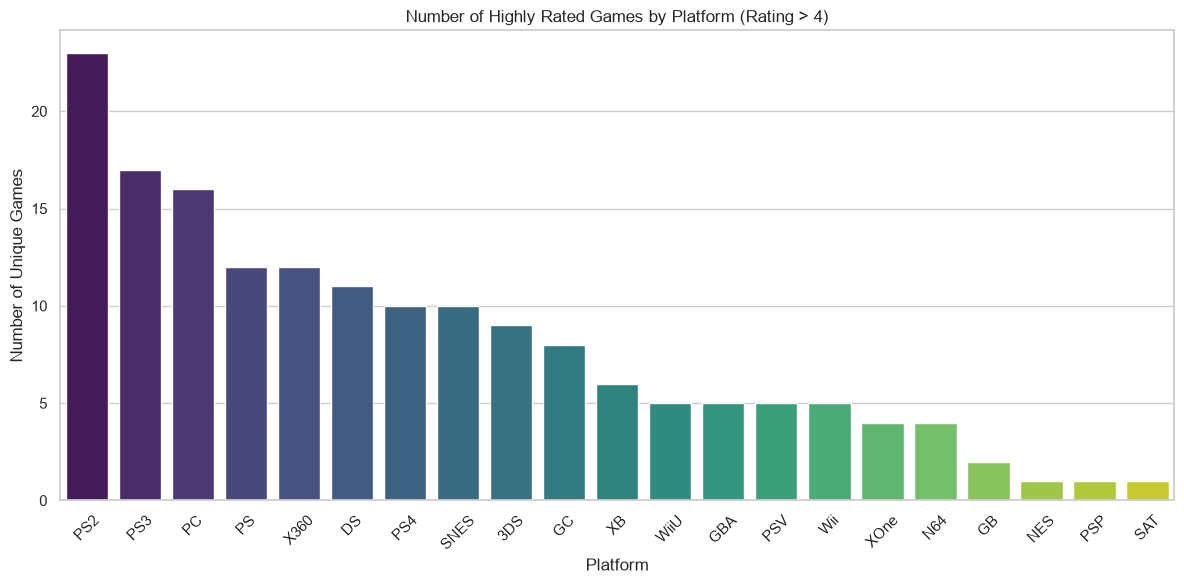

Platform with the most highly rated matched games:


,Platform,Number_of_High_Rated_Games
0,PS2,23


In [48]:

# Question 23: Highly rated games by platform

high_rated = merged[merged["Rating"] > 4.0].copy()

platform_ratings = (
    high_rated.groupby("Platform")["Merge_Title"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index(name="Number_of_High_Rated_Games")
)

display(platform_ratings)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=platform_ratings,
    x="Platform",
    y="Number_of_High_Rated_Games",
    hue="Platform",
    palette="viridis",
    legend=False
)

plt.title("Number of Highly Rated Games by Platform (Rating > 4)")
plt.xlabel("Platform")
plt.ylabel("Number of Unique Games")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Platform with the most highly rated matched games:")
display(platform_ratings.head(1))


### Chart Interpretation — Highly Rated Games by Platform

##### 1. Why did you pick this specific chart?
A bar chart counts titles above the chosen rating threshold by platform, making the distribution of highly rated matched titles easy to compare.

##### 2. What insights were found?
The chart shows which platforms have the largest number of matched titles rated above 4.0. Counts are influenced by how many games from each platform are represented in the source data.

##### 3. Will the gained insights help create a positive business impact?
This view can help compare the available sample of highly rated titles and identify platforms for deeper quality or audience research.

##### Are there any insights that lead to negative growth? Justify with specific reasons.
A platform with more qualifying games may simply have more records or more matched titles. Compare proportions and sample sizes before drawing conclusions about overall platform quality.


,Year,Number_of_Records,Total_Global_Sales
24,2004.0,749,417.22
25,2005.0,944,460.33
26,2006.0,1024,527.48
27,2007.0,1218,615.46
28,2008.0,1455,691.76
29,2009.0,1449,670.20
30,2010.0,1285,614.86
31,2011.0,1148,517.72
32,2012.0,669,368.68
33,2013.0,556,370.43


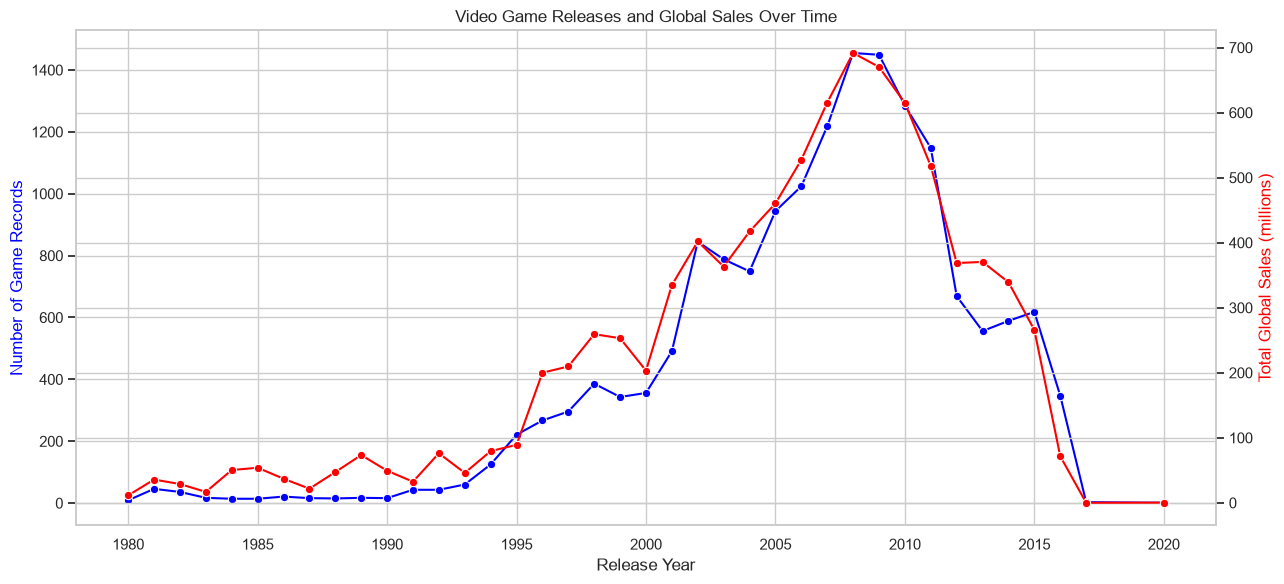

In [49]:

# Question 24: Release trend and global sales over time

sales["Year"] = pd.to_numeric(sales["Year"], errors="coerce")

yearly_trend = (
    sales.dropna(subset=["Year"])
    .groupby("Year", as_index=False)
    .agg(
        Number_of_Records=("Name", "count"),
        Total_Global_Sales=("Global_Sales", "sum")
    )
    .sort_values("Year")
)

display(yearly_trend.tail(15))

fig, ax1 = plt.subplots(figsize=(13, 6))

sns.lineplot(
    data=yearly_trend,
    x="Year",
    y="Number_of_Records",
    ax=ax1,
    color="blue",
    marker="o"
)

ax1.set_xlabel("Release Year")
ax1.set_ylabel("Number of Game Records", color="blue")
ax1.set_title("Video Game Releases and Global Sales Over Time")

ax2 = ax1.twinx()
sns.lineplot(
    data=yearly_trend,
    x="Year",
    y="Total_Global_Sales",
    ax=ax2,
    color="red",
    marker="o"
)

ax2.set_ylabel("Total Global Sales (millions)", color="red")

plt.tight_layout()
plt.show()


### Chart Interpretation — Release Trend and Global Sales Over Time

##### 1. Why did you pick this specific chart?
A time-series chart makes it possible to compare the number of recorded releases and cumulative global sales by year.

##### 2. What insights were found?
The sales dataset's strongest annual global sales totals occur around 2008 and 2009, with 2008 the highest in this file. These are historical totals from the dataset and may reflect the coverage and lifecycle of the included platforms.

##### 3. Will the gained insights help create a positive business impact?
The trend can provide historical context for portfolio planning and encourage investigation of release timing, platform generations, and genre shifts.

##### Are there any insights that lead to negative growth? Justify with specific reasons.
A decline after a peak does not necessarily mean declining player demand; data coverage, platform transition, and missing or estimated years can affect the pattern. Historical trends should not be extrapolated without current data.


Wishlist-sales correlation: -0.07


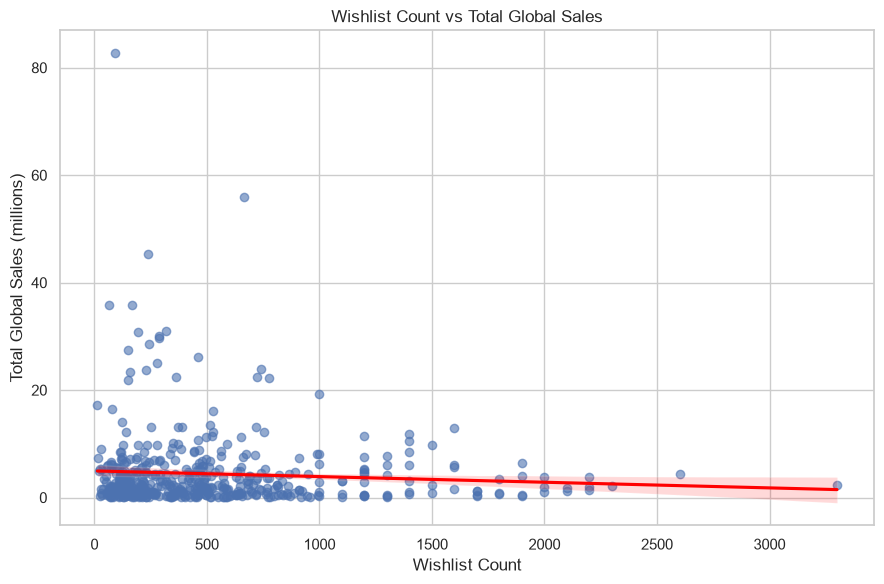

In [50]:

# Question 25: Wishlist vs global sales

wishlist_sales = merged_by_game.dropna(
    subset=["Wishlist", "Total_Global_Sales"]
)

wishlist_corr = wishlist_sales["Wishlist"].corr(
    wishlist_sales["Total_Global_Sales"]
)

print("Wishlist-sales correlation:", round(wishlist_corr, 3))

plt.figure(figsize=(9, 6))
sns.regplot(
    data=wishlist_sales,
    x="Wishlist",
    y="Total_Global_Sales",
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "red"}
)

plt.title("Wishlist Count vs Total Global Sales")
plt.xlabel("Wishlist Count")
plt.ylabel("Total Global Sales (millions)")
plt.tight_layout()
plt.show()


### Chart Interpretation — Wishlist Count vs Global Sales

##### 1. Why did you pick this specific chart?
A scatter plot with a fitted trend line is useful for exploring the direction and strength of association between wishlist counts and global sales.

##### 2. What insights were found?
The printed correlation coefficient summarizes the linear association for matched games with both values available. Even a positive association would not mean wishlists convert directly into sales, and a weak association would suggest wishlist count alone is insufficient.

##### 3. Will the gained insights help create a positive business impact?
The analysis can help evaluate whether wishlist data is useful as one of several demand signals and motivate the collection of conversion data.

##### Are there any insights that lead to negative growth? Justify with specific reasons.
Treating wishlist counts as expected sales can lead to overforecasting. Matching errors, missing engagement values, different time windows, and blockbuster outliers may affect the observed correlation.


,Genre,Average_Plays,Average_Global_Sales,Number_of_Games
8,Shooter,7813.114754,6.597377,61
3,Misc,7730.000000,6.018000,10
6,Racing,7061.538462,9.720769,13
0,Action,6581.147887,4.271620,142
4,Platform,6124.734177,4.882911,79
10,Sports,5955.875000,14.375000,8
1,Adventure,5102.548387,1.225161,31
7,Role-Playing,5055.764706,2.692588,85
2,Fighting,4101.416667,3.298750,24
11,Strategy,3974.545455,1.077273,11


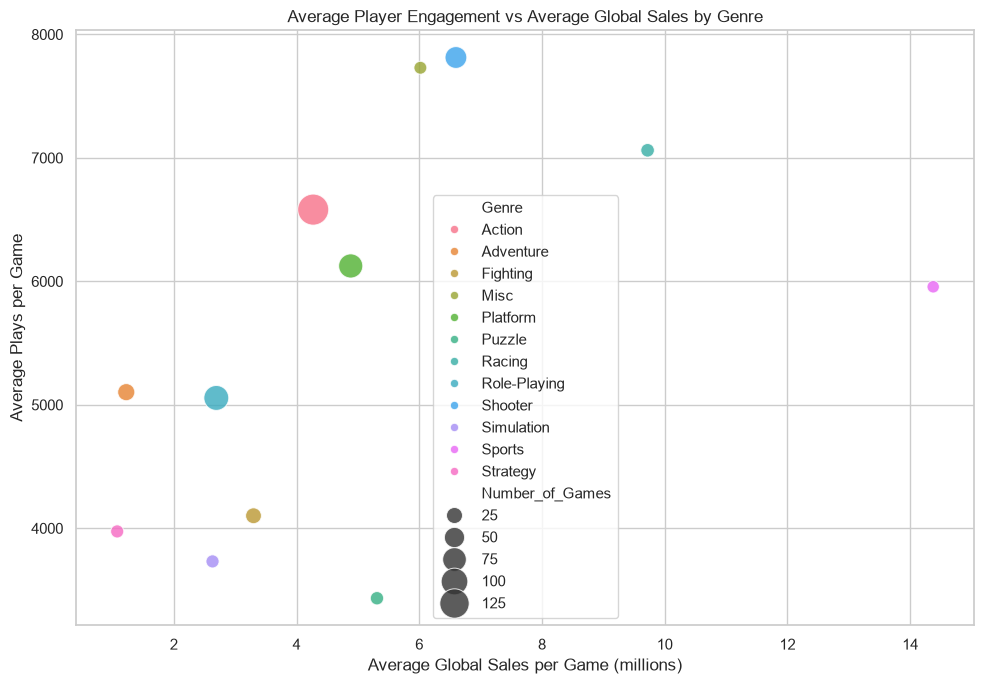

In [51]:

# Question 26: Engagement vs sales by genre

genre_engagement = (
    merged_by_game.dropna(
        subset=["Genre", "Plays", "Total_Global_Sales"]
    )
    .groupby("Genre", as_index=False)
    .agg(
        Average_Plays=("Plays", "mean"),
        Average_Global_Sales=("Total_Global_Sales", "mean"),
        Number_of_Games=("Merge_Title", "nunique")
    )
)

display(
    genre_engagement.sort_values(
        "Average_Plays", ascending=False
    )
)

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=genre_engagement,
    x="Average_Global_Sales",
    y="Average_Plays",
    size="Number_of_Games",
    hue="Genre",
    sizes=(80, 500),
    alpha=0.8
)

plt.title("Average Player Engagement vs Average Global Sales by Genre")
plt.xlabel("Average Global Sales per Game (millions)")
plt.ylabel("Average Plays per Game")
plt.tight_layout()
plt.show()


### Chart Interpretation — Engagement vs Sales by Genre

##### 1. Why did you pick this specific chart?
A scatter plot compares average plays with average global sales across genres, allowing both engagement and commercial performance to be viewed together.

##### 2. What insights were found?
Genres may differ in average plays and average sales, and the relationship may not be uniform. Each genre's number of matched games matters because averages from small groups are less stable.

##### 3. Will the gained insights help create a positive business impact?
The comparison can identify genres for deeper investigation where engagement and sales appear aligned or diverge.

##### Are there any insights that lead to negative growth? Justify with specific reasons.
High plays do not guarantee high sales, and averages can hide title-level variation. The matched sample may not represent all games in either dataset, so avoid treating genre-level associations as causal.


Times Listed vs Rating correlation: 0.443
Backlogs vs Rating correlation: 0.439


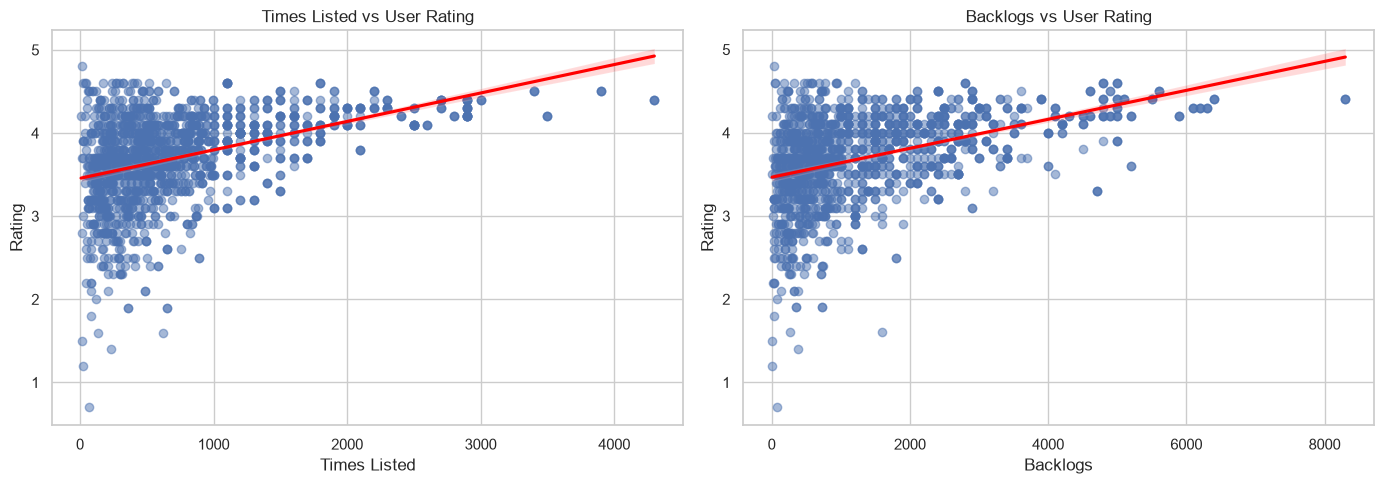

In [52]:

# Question 27: Listings and backlogs vs ratings

engagement_rating = games_data.dropna(
    subset=["Times Listed", "Backlogs", "Rating"]
)

# Calculate correlations
listed_corr = engagement_rating["Times Listed"].corr(
    engagement_rating["Rating"]
)

backlog_corr = engagement_rating["Backlogs"].corr(
    engagement_rating["Rating"]
)

print("Times Listed vs Rating correlation:", round(listed_corr, 3))
print("Backlogs vs Rating correlation:", round(backlog_corr, 3))

# Create two scatterplots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.regplot(
    data=engagement_rating,
    x="Times Listed",
    y="Rating",
    ax=axes[0],
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"}
)
axes[0].set_title("Times Listed vs User Rating")

sns.regplot(
    data=engagement_rating,
    x="Backlogs",
    y="Rating",
    ax=axes[1],
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"}
)
axes[1].set_title("Backlogs vs User Rating")

plt.tight_layout()
plt.show()


### Chart Interpretation — Times Listed / Backlogs vs Ratings

##### 1. Why did you pick this specific chart?
Scatter plots are appropriate for examining the relationship between ratings and two engagement measures: how often games are listed and how many players have them in their backlogs.

##### 2. What insights were found?
The correlation values printed above the plots indicate the direction and strength of linear association in the available records. A weak relationship would mean these engagement measures do not closely track ratings in a simple linear way.

##### 3. Will the gained insights help create a positive business impact?
The plots can help teams avoid assuming that popularity signals and ratings measure the same aspect of player response.

##### Are there any insights that lead to negative growth? Justify with specific reasons.
Backlog size may indicate interest without completion, and listing counts may reflect visibility rather than satisfaction. Correlation does not establish cause and may be affected by outliers and missing records.


,Genres_List,Average_Plays,Average_Playing,Average_Wishlist,Number_of_Games
6,MOBA,10166.666667,887.666667,56.333333,2
16,Shooter,7565.726496,241.196581,750.794872,254
14,Racing,7197.000000,131.166667,234.190476,37
9,Platform,7162.522796,215.231003,716.352584,236
21,Turn Based Strategy,6834.181818,410.767677,969.656566,70
0,Adventure,6591.593843,305.871897,923.405164,706
2,Brawler,6518.273885,373.171975,1180.222930,103
13,RPG,6381.209302,422.534884,995.255814,355
18,Sport,5977.320000,126.240000,182.960000,20
17,Simulator,5738.080000,323.192000,560.032000,92


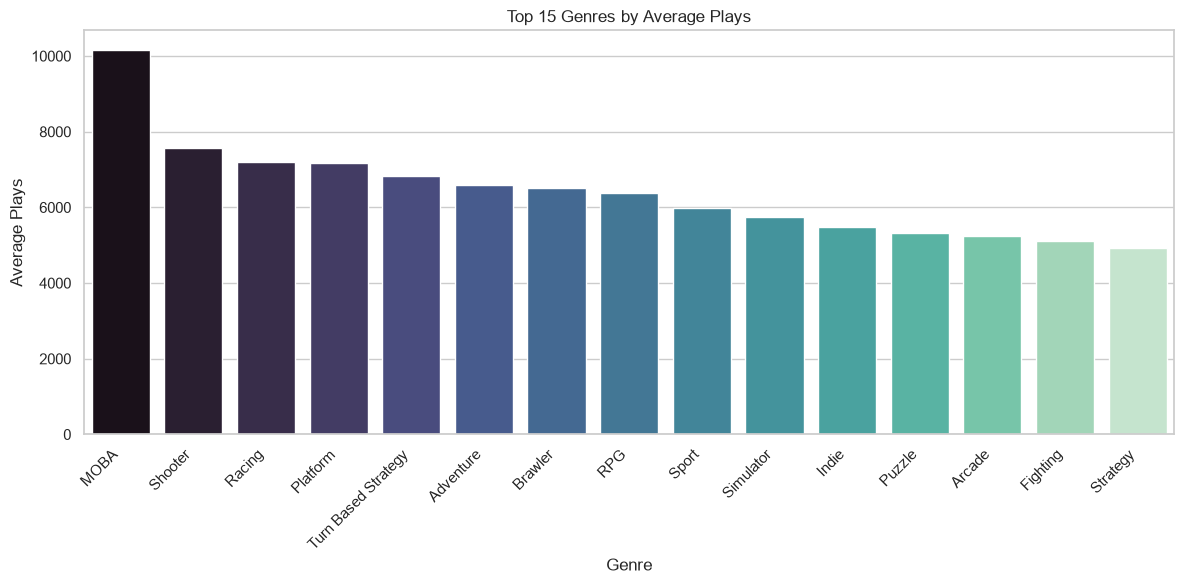

In [53]:

# Question 28: Engagement across genres

import ast

genre_games = games_data.copy()

# Convert string representations of lists into actual lists
def parse_genres(value):
    if pd.isna(value):
        return []

    if isinstance(value, list):
        return value

    try:
        parsed = ast.literal_eval(str(value))
        if isinstance(parsed, list):
            return parsed
    except (ValueError, SyntaxError):
        pass

    return [str(value)]

genre_games["Genres_List"] = genre_games["Genres"].apply(parse_genres)

# One row per game-genre combination
genre_games = genre_games.explode("Genres_List")
genre_games = genre_games.dropna(subset=["Genres_List"])
genre_games = genre_games[
    genre_games["Genres_List"].astype(str).str.strip() != ""
]

engagement_by_genre = (
    genre_games.groupby("Genres_List", as_index=False)
    .agg(
        Average_Plays=("Plays", "mean"),
        Average_Playing=("Playing", "mean"),
        Average_Wishlist=("Wishlist", "mean"),
        Number_of_Games=("Title", "nunique")
    )
    .sort_values("Average_Plays", ascending=False)
)

display(engagement_by_genre)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=engagement_by_genre.head(15),
    x="Genres_List",
    y="Average_Plays",
    hue="Genres_List",
    palette="mako",
    legend=False
)

plt.title("Top 15 Genres by Average Plays")
plt.xlabel("Genre")
plt.ylabel("Average Plays")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


### Chart Interpretation — Engagement Across Genres

##### 1. Why did you pick this specific chart?
Comparing engagement metrics across genres helps explore whether plays, wishlists, playing counts, or backlogs vary by the types of games players follow.

##### 2. What insights were found?
The chart compares the engagement measures available in the dataset across genres. Because games may have multiple genre tags, a title can contribute to more than one category.

##### 3. Will the gained insights help create a positive business impact?
The results can support more targeted follow-up analysis and help identify genres with stronger observed engagement in this dataset.

##### Are there any insights that lead to negative growth? Justify with specific reasons.
Multi-genre tags can mean category totals overlap, and large franchises can dominate averages or totals. Interpret the chart with its aggregation method and sample sizes in mind.


Top 15 Genre + Platform combinations:


,Genre,Platform,Total_Global_Sales,Number_of_Records
13,Action,PS3,307.88,380
265,Sports,Wii,292.06,261
219,Shooter,X360,278.50,201
258,Sports,PS2,273.41,400
12,Action,PS2,272.76,348
21,Action,X360,242.67,324
93,Misc,Wii,221.06,280
210,Shooter,PS3,196.04,156
158,Racing,PS2,156.28,216
267,Sports,X360,139.12,220


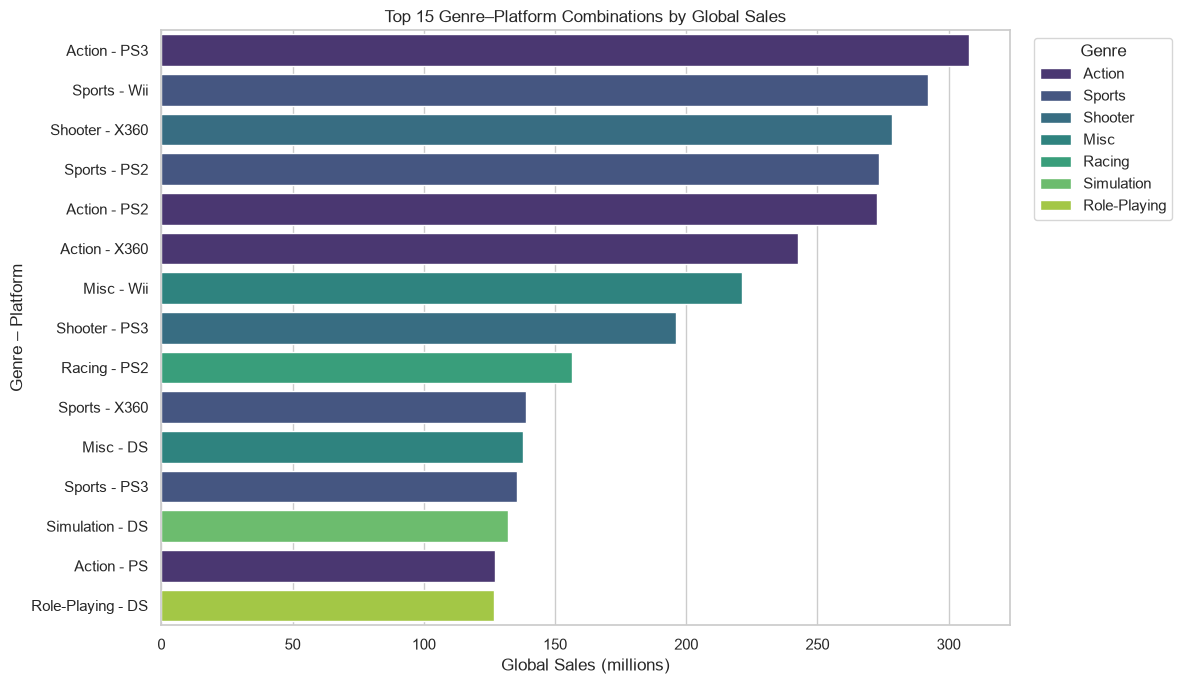

In [54]:

# Question 29: Genre and platform performance

genre_platform_sales = (
    sales.groupby(["Genre", "Platform"], as_index=False)
    .agg(
        Total_Global_Sales=("Global_Sales", "sum"),
        Number_of_Records=("Name", "count")
    )
    .sort_values("Total_Global_Sales", ascending=False)
)

print("Top 15 Genre + Platform combinations:")
display(genre_platform_sales.head(15))

top_15_combinations = genre_platform_sales.head(15).copy()
top_15_combinations["Genre_Platform"] = (
    top_15_combinations["Genre"] + " - " +
    top_15_combinations["Platform"]
)

plt.figure(figsize=(12, 7))
sns.barplot(
    data=top_15_combinations,
    x="Total_Global_Sales",
    y="Genre_Platform",
    hue="Genre",
    dodge=False,
    palette="viridis"
)

plt.title("Top 15 Genre–Platform Combinations by Global Sales")
plt.xlabel("Global Sales (millions)")
plt.ylabel("Genre – Platform")
plt.legend(title="Genre", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


### Chart Interpretation — Genre and Platform Performance

##### 1. Why did you pick this specific chart?
A ranked bar chart of genre-platform combinations makes it possible to identify combinations with the largest recorded global sales.

##### 2. What insights were found?
The top combinations indicate that sales performance varies not only by genre but also by platform. The table above the chart provides the exact ranked combinations from the source data.

##### 3. Will the gained insights help create a positive business impact?
The comparison can inform historical portfolio review and suggest combinations for further market research.

##### Are there any insights that lead to negative growth? Justify with specific reasons.
A high historical total may be driven by many titles or a long platform lifecycle, not superior per-title performance. This analysis should not be treated as a current market forecast.


,North America,Europe,Japan,Other Regions
Genre,,,,
Action,877.54,524.92,159.49,187.35
Adventure,105.67,64.08,51.99,16.81
Fighting,221.92,100.22,87.35,36.24
Misc,404.67,213.93,107.72,75.22
Platform,447.05,201.13,130.77,51.59
Puzzle,123.78,50.77,57.31,12.55
Racing,359.42,238.38,56.69,77.27
Role-Playing,327.28,188.05,352.26,59.61
Shooter,582.59,313.24,38.28,102.69


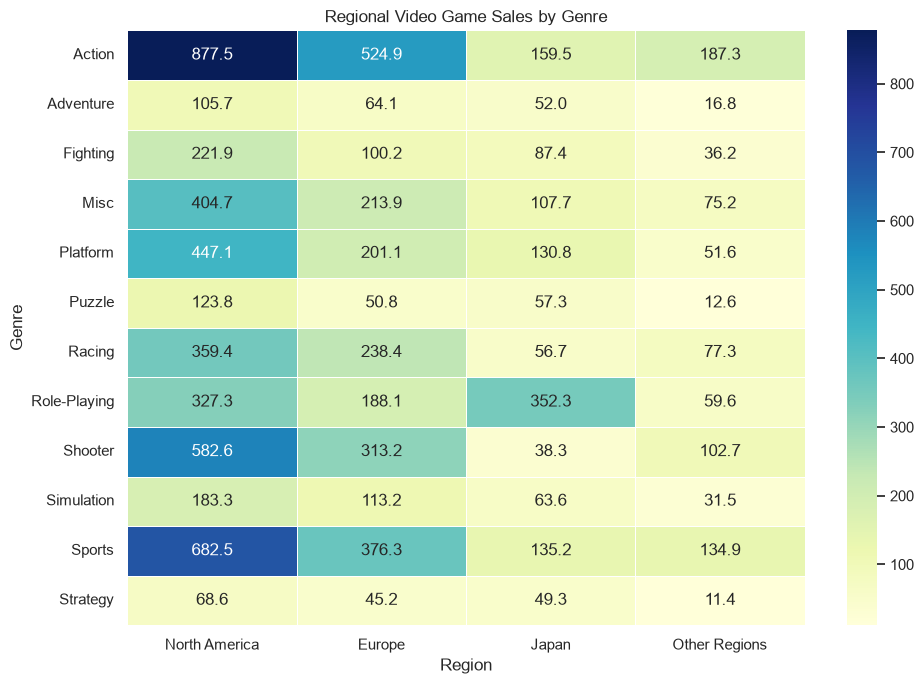

In [55]:

# Question 30: Regional sales heatmap by genre

regional_sales = (
    sales.groupby("Genre")[
        ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]
    ]
    .sum()
)

# Rename columns for readability
regional_sales = regional_sales.rename(columns={
    "NA_Sales": "North America",
    "EU_Sales": "Europe",
    "JP_Sales": "Japan",
    "Other_Sales": "Other Regions"
})

display(regional_sales)

plt.figure(figsize=(10, 7))
sns.heatmap(
    regional_sales,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Regional Video Game Sales by Genre")
plt.xlabel("Region")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()


### Chart Interpretation — Regional Sales Heatmap by Genre

##### 1. Why did you pick this specific chart?
A heatmap encodes sales magnitude with colour, making regional differences across genres easy to scan in one compact view.

##### 2. What insights were found?
North America and Europe contribute large sales totals for Action and Sports, while Japan has a comparatively stronger contribution to Role-Playing games. The heatmap supports the view that regional demand patterns vary by genre.

##### 3. Will the gained insights help create a positive business impact?
The results can inform follow-up questions about localization, regional promotion, and genre-specific audience research.

##### Are there any insights that lead to negative growth? Justify with specific reasons.
The regional totals are historical and may reflect the platforms and years represented in the dataset. They do not measure current demand, profit, or the effect of localization, so they should not be used alone to allocate budgets.


## Key Findings

- **Genre performance is uneven:** Action has the highest cumulative global sales in the historical sales dataset, at approximately 1,750 million units. Sports and Shooter also contribute substantially. This shows that historical sales are concentrated differently across genres rather than being evenly distributed.

- **Total sales and average sales tell different stories:** A genre can have high total sales because it contains many recorded games, while another genre may perform better on a per-game basis. Comparing both measures gives a more complete view of genre performance than relying on total sales alone.

- **Platform catalogues differ in size:** PS2 and DS have among the largest numbers of game records in the dataset. This highlights differences in historical catalogue coverage, but the number of records alone does not establish which platform was most profitable or most popular with current players.

- **Regional preferences are not identical:** The regional sales analysis shows that North America and Europe contribute strongly to many genres, while Role-Playing games have a comparatively strong contribution in Japan. This indicates that genre performance should be examined by region rather than assuming the same audience preferences everywhere.

- **Engagement measures capture different aspects of interest:** Ratings describe user evaluations, while plays, wishlists, backlogs, and listing counts reflect different forms of engagement or attention. A game may attract attention without necessarily receiving the highest rating, so these indicators should be interpreted separately before comparing them.

- **Sales and engagement cannot be compared for every game:** The title-matching process links only a subset of records across the two datasets. Differences in title formats, editions, and dataset coverage limit the conclusions that can be drawn from merged charts. Results from matched games may not represent the entire historical sales catalogue.

- **Relationships need to be interpreted cautiously:** The genre-level comparison of average plays and average global sales can reveal differences between engagement and commercial performance. However, a relationship in this chart does not prove that higher engagement causes higher sales, particularly because the datasets cover different populations and periods.

## Business Recommendations

1. **Evaluate genres using multiple measures.** Compare cumulative sales, average sales per game, and the number of recorded titles before drawing conclusions about genre performance. This helps distinguish large catalogues from stronger per-title performance.

2. **Consider regional differences in genre performance.** The observed differences between regional sales suggest that publishers should investigate local preferences when evaluating game positioning, localization, and marketing plans. Current market data would be needed before applying these historical patterns to present-day decisions.

3. **Use engagement indicators together, not interchangeably.** Ratings, plays, wishlists, and backlogs provide different perspectives on user response. Combining them can support further investigation into games that attract attention, receive strong evaluations, or remain on players' lists.

4. **Investigate games with different sales and engagement patterns.** Games with strong historical sales but lower observed engagement, or strong engagement but lower recorded sales, may be useful candidates for closer study. These differences should first be validated because the two datasets may cover different periods and audiences.

5. **Improve title matching before making game-level comparisons.** Review unmatched titles and ambiguous matches, especially for important games. Report how many records were matched and unmatched so that conclusions are not mistaken for results from the complete catalogue.

6. **Avoid using sales volume as a substitute for profitability.** The analysis identifies historical sales patterns, not profit. Revenue, development costs, marketing expenditure, and player-retention data would be needed to evaluate financial success more directly.

## Conclusion

This Exploratory Data Analysis provided valuable insights into video game sales, platform performance, regional preferences, and player engagement. The analysis revealed that **Action games contributed the highest cumulative global sales** in the historical sales dataset, while genres such as Sports and Shooter also demonstrated significant market potential. Comparing total sales with average sales per game helped develop a clearer understanding of how genre performance can vary across different measures.

The analysis of regional sales highlighted differences in gaming preferences across North America, Europe, and Japan, demonstrating the importance of considering regional interests when planning marketing and game distribution strategies. In addition, exploring ratings, plays, wishlists, and backlogs provided a broader perspective on player engagement beyond sales figures alone.

One of the key learnings from this project was the importance of combining multiple metrics rather than relying on a single indicator to evaluate performance. The project also strengthened my understanding of data cleaning, exploratory analysis, visualization, data merging, and interpreting patterns to generate meaningful insights.

Overall, this project demonstrates how **data-driven analysis can help identify successful genres, understand audience preferences, and uncover opportunities for further investigation**. Although the datasets have limitations, the findings provide a useful foundation for deeper analysis using more complete and current data. This project has strengthened my ability to transform raw data into clear visual insights and practical, evidence-based recommendations.